# Практическая работа 9–10. Эволюционные алгоритмы оптимизации

**Выбранный вариант**

| Что | Выбор |
|---|---|
| Оптимизируемая функция | **функция Растригина**, $n = 2$, область $-5.12 \le x, y \le 5.12$, глобальный минимум $f(0, 0) = 0$ |
| Классический алгоритм | **метод Ньютона** (`scipy.optimize.minimize(method="Newton-CG")` с аналитическими градиентом и гессианом) |
| Эволюционные алгоритмы | все пять из задания: **генетический (GA)**, **рой частиц (PSO)**, **муравьиный (ACO, непрерывная версия ACO$_\mathbb{R}$)**, **пчелиный (Bees Algorithm)**, **дифференциальная эволюция (DE)** |
| Данные для части C | `sklearn.datasets.load_breast_cancer` (569 объектов, 30 признаков, 2 класса) |
| ЭА для части C | дифференциальная эволюция (лучший алгоритм по итогам части B) |

**Содержание**

0. Подготовка окружения и тестовая функция
1. **Часть A.** Изучение эволюционных алгоритмов (теория + демонстрация библиотек из задания)
2. **Часть B.** Оптимизация многоэкстремальной функции: метод Ньютона против ЭА
   - B.1–B.2 функция и её 3D-визуализация (п. 4)
   - B.3 метод Ньютона
   - B.4 собственные реализации ЭА
   - B.5 подбор параметров по минимуму дисперсии (п. 1)
   - B.6 100 прогонов: среднее и дисперсия финального значения (п. 1)
   - B.7 время достижения глобального экстремума (п. 2)
   - B.8 время нахождения последнего экстремума при остановке по числу поколений (п. 3)
   - B.9 графики сходимости (п. 4)
   - B.10 сводные таблицы (п. 5) и выводы
3. **Часть C.** Подбор гиперпараметров SVM, kNN и RF эволюционным алгоритмом

> Блокнот целиком выполняется примерно за 8–12 минут на стандартной CPU-среде Colab (GPU не нужен); самая долгая часть — подбор параметров в B.5 (≈3 мин) и RF в части C (≈3 мин). Общее время выводится в последней ячейке.

## 0. Подготовка окружения

In [1]:
# Библиотеки из задания (в Colab устанавливаются за ~10–20 с)
%pip install -q geneticalgorithm pyswarm bees-algorithm PyACO

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, io, random, itertools, warnings, contextlib
NOTEBOOK_T0 = time.perf_counter()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from cycler import cycler
from IPython.display import display
from scipy.optimize import minimize, differential_evolution

# Алгоритмы в порядке задания; каждому закреплён свой цвет на всех графиках
ALGOS = ['GA', 'PSO', 'ACO', 'Bees', 'DE']
ALGO_NAMES = {'GA': 'Генетический', 'PSO': 'Рой частиц', 'ACO': 'Муравьиный (ACO_R)',
              'Bees': 'Пчелиный', 'DE': 'Дифф. эволюция', 'Newton': 'Метод Ньютона'}
COLORS = {'GA': '#2a78d6', 'PSO': '#eb6834', 'ACO': '#1baf7a', 'Bees': '#eda100',
          'DE': '#e87ba4', 'Newton': '#52514e'}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    'blue_ramp', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8984',
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.8,
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
    'lines.linewidth': 1.8, 'axes.prop_cycle': cycler(color=[COLORS[a] for a in ALGOS]),
})
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)

### Тестовая функция — функция Растригина

$$f(\mathbf{x}) = A n + \sum_{i=1}^{n}\left[x_i^2 - A\cos(2\pi x_i)\right],\qquad A = 10,\; n = 2,\; -5.12 \le x_i \le 5.12 .$$

Глобальный минимум $f(0,0)=0$. Для метода Ньютона нужны производные — они вычисляются аналитически:

$$\frac{\partial f}{\partial x_i} = 2x_i + 2\pi A\sin(2\pi x_i), \qquad
\frac{\partial^2 f}{\partial x_i^2} = 2 + 4\pi^2 A\cos(2\pi x_i), \qquad \frac{\partial^2 f}{\partial x_i \partial x_j} = 0\; (i \ne j).$$

`EvalLogger` — обёртка, которая считает вызовы функции и запоминает лучшее значение после каждого вызова; она нужна, чтобы одинаково построить кривые сходимости для разных библиотек.

In [3]:
A_RASTR = 10.0
LB = np.array([-5.12, -5.12])
UB = np.array([5.12, 5.12])
F_STAR = 0.0          # известный глобальный минимум
X_STAR = np.zeros(2)  # точка глобального минимума
EPS = 1e-4            # точность, с которой считаем глобальный экстремум найденным


def rastrigin(X):
    """Функция Растригина. X: вектор (n,) -> число или матрица (N, n) -> вектор (N,)."""
    X = np.asarray(X, dtype=float)
    return A_RASTR * X.shape[-1] + np.sum(X**2 - A_RASTR * np.cos(2 * np.pi * X), axis=-1)


def rastrigin_grad(x):
    return 2 * x + 2 * np.pi * A_RASTR * np.sin(2 * np.pi * x)


def rastrigin_hess(x):
    return np.diag(2 + 4 * np.pi**2 * A_RASTR * np.cos(2 * np.pi * x))


class EvalLogger:
    """Обёртка над целевой функцией: число вызовов и лучшее значение после каждого вызова."""
    def __init__(self, func):
        self.func, self.best, self.hist = func, np.inf, []

    def __call__(self, x):
        value = float(self.func(x))
        self.best = min(self.best, value)
        self.hist.append(self.best)
        return value

    @property
    def n(self):
        return len(self.hist)


print('f(0, 0) =', rastrigin(X_STAR), '| f(1, 1) =', rastrigin(np.ones(2)), '| grad(0, 0) =', rastrigin_grad(X_STAR))

f(0, 0) = 0.0 | f(1, 1) = 2.0 | grad(0, 0) = [0. 0.]


---
# Часть A. Изучение эволюционных алгоритмов

### A.0 Общая схема

Эволюционные (популяционные, метаэвристические) алгоритмы ищут экстремум, **не используя производных**. Они работают с **популяцией** решений и на каждой итерации (*поколении*) повторяют один цикл:

1. **оценка** — для каждого решения считается функция соответствия (целевая функция, *fitness*);
2. **отбор** — лучшие решения получают больше шансов передать информацию дальше;
3. **вариация** — из отобранных строятся новые решения (скрещивание, мутация, перелёт частицы, выбор пути муравьём, локальный поиск пчёл…);
4. **замещение** — формируется новое поколение.

Ключевой компромисс — между **исследованием** (поиск новых областей, чтобы не застрять в локальном минимуме) и **использованием** (уточнение лучшего найденного решения). Параметры алгоритма задают этот баланс. Алгоритмы стохастические, поэтому результат одного прогона — случайная величина. Сравнивать их надо по многим прогонам, через среднее и дисперсию; это и делается в части B.

Ниже для каждого из пяти алгоритмов из задания: идея, основные формулы и параметры, затем короткий запуск соответствующей библиотеки на функции Растригина с бюджетом ≈3000 вычислений функции.

### A.1 Генетический алгоритм (GA)

**Идея** (Holland, 1975): моделируется естественный отбор. Решение кодируется *хромосомой* (двоичной строкой или вектором вещественных чисел). Новое поколение получается так:

* **селекция** родителей — рулетка, ранговая или *турнирная* (из $k$ случайных особей берётся лучшая);
* **скрещивание (кроссовер)** с вероятностью $p_c$ — одноточечное, двухточечное, равномерное; для вещественных генов также арифметическое и BLX-α: потомок равномерно берётся из отрезка $[\min - \alpha I, \max + \alpha I]$, где $I = |x^{(1)}_j - x^{(2)}_j|$;
* **мутация** с вероятностью $p_m$ на ген — инверсия бита или гауссов шум $x_j \leftarrow x_j + \mathcal N(0, \sigma^2)$;
* **элитизм** — несколько лучших особей переходят в следующее поколение без изменений.

**Параметры:** размер популяции, $p_c$, $p_m$ (и $\sigma$), доля элиты, тип кроссовера, число поколений.

**Библиотека** [`geneticalgorithm`](https://pypi.org/project/geneticalgorithm/): класс `geneticalgorithm(function, dimension, variable_type, variable_boundaries, algorithm_parameters)`. Минимизирует функцию, поддерживает переменные типов `real` / `int` / `bool`. Параметры передаются словарём: `max_num_iteration`, `population_size`, `mutation_probability`, `elit_ratio`, `crossover_probability`, `parents_portion`, `crossover_type`.

In [4]:
from geneticalgorithm import geneticalgorithm as GeneticAlgorithmLib

lib_results, lib_curves = {}, {}   # сводка по демонстрациям библиотек

np.random.seed(0)                  # библиотека использует глобальный генератор numpy
log = EvalLogger(rastrigin)
t0 = time.perf_counter()
ga_lib = GeneticAlgorithmLib(
    function=log, dimension=2, variable_type='real',
    variable_boundaries=np.column_stack([LB, UB]),
    algorithm_parameters={'max_num_iteration': 100, 'population_size': 30,
                          'mutation_probability': 0.1, 'elit_ratio': 0.02,
                          'crossover_probability': 0.5, 'parents_portion': 0.3,
                          'crossover_type': 'uniform', 'max_iteration_without_improv': None},
    convergence_curve=False, progress_bar=False)
ga_lib.run()
lib_results['GA — geneticalgorithm'] = dict(x=np.round(ga_lib.output_dict['variable'], 5),
                                            f=ga_lib.output_dict['function'], nfev=log.n,
                                            time_s=time.perf_counter() - t0)
lib_curves['GA — geneticalgorithm'] = ('GA', log.hist)

 The best solution found:
 [0.00776963 0.01265983]

 Objective function:
 0.04375389152082221


### A.2 Алгоритм роя частиц (PSO)

**Идея** (Kennedy & Eberhart, 1995): частицы летают по пространству поиска, и каждая «помнит» свою лучшую точку $\mathbf p_i$. Рой «знает» лучшую точку $\mathbf g$ среди всех частиц. Скорость и положение обновляются так:

$$\mathbf v_i \leftarrow w\,\mathbf v_i + c_1 r_1(\mathbf p_i - \mathbf x_i) + c_2 r_2(\mathbf g - \mathbf x_i), \qquad \mathbf x_i \leftarrow \mathbf x_i + \mathbf v_i, \qquad r_1, r_2 \sim U(0,1).$$

**Параметры:** число частиц, инерция $w$ (большая — исследование, малая — уточнение), когнитивный $c_1$ и социальный $c_2$ коэффициенты, ограничение скорости $v_{\max}$. Классический устойчивый набор (Clerc, Kennedy): $w = 0.7298,\ c_1 = c_2 = 1.4962$.

**Библиотека** [`pyswarm`](https://pypi.org/project/pyswarm/): `pso(func, lb, ub, swarmsize, omega, phip, phig, maxiter, minstep, minfunc)`, где `omega` = $w$, `phip` = $c_1$, `phig` = $c_2$. Новые версии возвращают `OptimizeResult`, старые (0.6) — кортеж `(xopt, fopt)`; код ниже работает с обоими вариантами.

In [5]:
from pyswarm import pso as pso_lib

np.random.seed(0)
log = EvalLogger(rastrigin)
t0 = time.perf_counter()
res = pso_lib(log, LB, UB, swarmsize=30, maxiter=100, omega=0.7298, phip=1.4962, phig=1.4962,
              minstep=1e-12, minfunc=1e-12)
x_pso, f_pso = res if isinstance(res, tuple) else (res.x, res.fun)
lib_results['PSO — pyswarm'] = dict(x=np.round(x_pso, 5), f=f_pso, nfev=log.n, time_s=time.perf_counter() - t0)
lib_curves['PSO — pyswarm'] = ('PSO', log.hist)
print('PSO (pyswarm):', np.round(x_pso, 5), f_pso)

PSO (pyswarm): [1.e-05 1.e-05] 2.137953458714037e-08


### A.3 Муравьиный алгоритм (ACO)

**Идея** (Dorigo, 1992): муравьи строят решения на графе и оставляют на рёбрах **феромон**. Чем короче путь, тем больше феромона на его рёбрах, и тем чаще их выбирают следующие муравьи. Вероятность перехода $i \to j$:

$$p_{ij} = \frac{\tau_{ij}^{\alpha}\,\eta_{ij}^{\beta}}{\sum_{l \in \text{допустимые}} \tau_{il}^{\alpha}\,\eta_{il}^{\beta}}, \qquad \eta_{ij} = 1/d_{ij},$$

после итерации феромон испаряется и пополняется: $\tau_{ij} \leftarrow (1-\rho)\,\tau_{ij} + \sum_k Q/L_k$.

**Параметры:** число муравьёв, $\alpha$ (вес феромона), $\beta$ (вес эвристики), $\rho$ (испарение), $Q$, границы $\tau_{\min}, \tau_{\max}$.

**Библиотека** [`PyACO`](https://pypi.org/project/PyACO/) решает только **задачу коммивояжёра** на случайном графе. Это комбинаторная задача, функцию непрерывных переменных ею не оптимизировать. Ниже показан её штатный сценарий: `ACOSolver(num_of_ants, num_of_vertexes, Q, alpha, beta, rou, max_iterations, ...)`, где `rou` — доля **сохраняемого** феромона, $1-\rho$. Встроенная интерактивная анимация отключена, маршрут рисуется отдельно.

**Непрерывная версия ACO$_\mathbb{R}$** (Socha & Dorigo, 2008) используется в части B. Вместо матрицы феромонов хранится **архив** из $k$ лучших решений $s_1, \dots, s_k$, упорядоченных по качеству. Каждый муравей выбирает решение $s_l$ с вероятностью $p_l = \omega_l / \sum_r \omega_r$, где

$$\omega_l = \frac{1}{qk\sqrt{2\pi}}\exp\left(-\frac{(l-1)^2}{2q^2k^2}\right),$$

и генерирует новую точку из нормального распределения $\mathcal N\!\left(s_l^i,\ \sigma_l^i\right)$, $\ \sigma_l^i = \xi \sum_{e=1}^k |s_e^i - s_l^i|/(k-1)$. Затем архив снова усекается до $k$ лучших. Параметр $q$ отвечает за «локальность» (малое $q$ — поиск у лучшего решения), $\xi$ — аналог скорости испарения феромона.

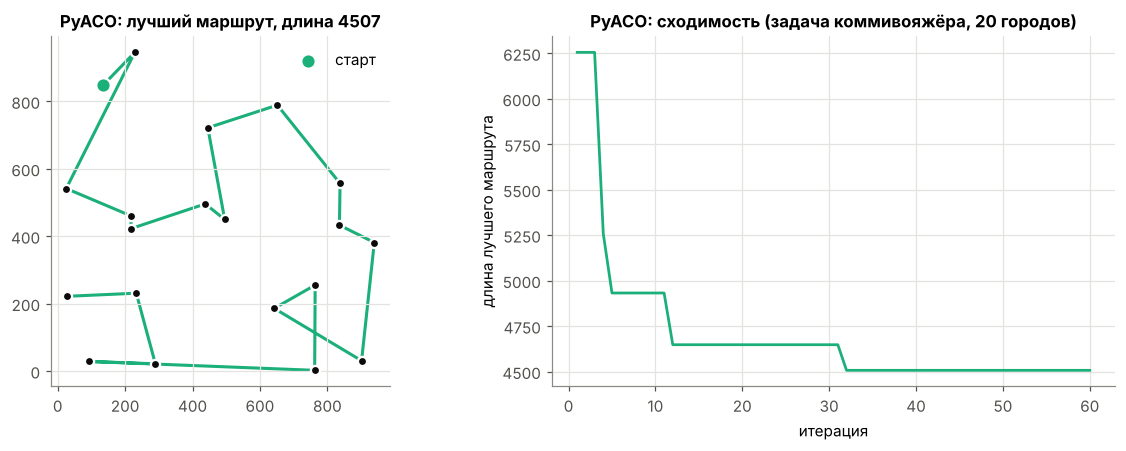

Время: 0.16 c; длина маршрута на 1-й итерации 6255 -> 4507


In [6]:
try:
    import PyACO.plot as aco_plot
    aco_plot.init_plot = lambda *a, **k: None      # отключаем интерактивную анимацию библиотеки
    aco_plot.play_plot = lambda *a, **k: None
    from PyACO.ACOSolver import ACOSolver

    random.seed(1)
    buf = io.StringIO()
    t0 = time.perf_counter()
    with contextlib.redirect_stdout(buf):          # библиотека печатает лучший путь на каждой итерации
        tsp = ACOSolver(num_of_ants=20, num_of_vertexes=20, Q=100, alpha=1, beta=3, rou=0.5,
                        max_iterations=60, initial_vertex=0, tau_min=0.01, tau_max=10,
                        ant_prob_random=0.05, super_not_change=30, plot_time=0)
        tsp.run_aco()
    t_tsp = time.perf_counter() - t0
    lengths = [float(line.split('[', 1)[1].split(',', 1)[0]) for line in buf.getvalue().splitlines() if '[' in line]
    best_len, best_path = tsp.m_super_ant
    coords = np.array(tsp.m_graph.m_coordinates)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    ax1.plot(coords[best_path, 0], coords[best_path, 1], color=COLORS['ACO'], lw=2, zorder=1)
    ax1.scatter(coords[:, 0], coords[:, 1], s=36, color='#0b0b0b', edgecolor='white', lw=1.5, zorder=2)
    ax1.scatter(*coords[best_path[0]], s=90, color=COLORS['ACO'], edgecolor='white', lw=1.5, zorder=3, label='старт')
    ax1.set_title(f'PyACO: лучший маршрут, длина {best_len:.0f}')
    ax1.set_aspect('equal'); ax1.legend(loc='upper right')
    ax2.plot(np.arange(1, len(lengths) + 1), lengths, color=COLORS['ACO'])
    ax2.set_xlabel('итерация'); ax2.set_ylabel('длина лучшего маршрута')
    ax2.set_title('PyACO: сходимость (задача коммивояжёра, 20 городов)')
    plt.tight_layout(); plt.show()
    print(f'Время: {t_tsp:.2f} c; длина маршрута на 1-й итерации {lengths[0]:.0f} -> {best_len:.0f}')
except Exception as exc:
    print('PyACO недоступна в этой среде:', exc)

### A.4 Пчелиный алгоритм (Bees Algorithm)

**Идея** (Pham et al., 2005): моделируется поиск нектара пчелиной семьёй.

1. *Разведчики* случайно исследуют пространство; лучшие $nb$ точек становятся **участками** (*sites*), из них $ne$ лучших — **элитные**.
2. На каждый элитный участок направляется $nre$ пчёл-фуражиров, на обычный — $nrb$. Фуражиры ищут в **окрестности** участка размера $ngh$. Лучшая пчела окрестности становится новым центром участка.
3. Если участок не улучшился, его окрестность **сужается** (*neighbourhood shrinking*). После $stlim$ неудач подряд участок **бросается** (*site abandonment*), а лучшее найденное на нём решение запоминается.
4. Остальные пчёлы продолжают случайный (глобальный) поиск.

**Параметры:** $ns$ (разведчики), $nb$, $ne$, $nrb$, $nre$, $ngh$, коэффициент сужения, $stlim$. Близкий по духу алгоритм — ABC (Artificial Bee Colony, Karaboga): рабочие, наблюдатели и разведчики.

**Библиотека** [`bees-algorithm`](https://pypi.org/project/bees-algorithm/) (L. Baronti). В версии 2.x: `BeesAlgorithm(objective, (lower, upper), BeesParameters(n_scouts, n_sites, n_elite_sites, n_foragers_site, n_foragers_elite, stagnation_limit, shrink_factor), direction='minimize')`. В версии 1.x — `BeesAlgorithm(score_function, range_min, range_max, ns, nb, ne, nrb, nre, stlim)`, и функция там максимизируется. Код поддерживает оба API.

In [7]:
log = EvalLogger(rastrigin)
t0 = time.perf_counter()
try:
    from bees_algorithm import BeesAlgorithm, BeesParameters          # API версии 2.x
    bees_lib = BeesAlgorithm(log, (LB.tolist(), UB.tolist()),
                             BeesParameters(n_scouts=5, n_sites=5, n_elite_sites=2, n_foragers_site=3,
                                            n_foragers_elite=8, stagnation_limit=10),
                             direction='minimize', seed=0)
    for _ in bees_lib.iterate(max_iterations=100):
        pass
    x_bees, f_bees = bees_lib.best.position, bees_lib.best.score
except ImportError:                                                    # API версии 1.x (максимизация)
    from bees_algorithm import BeesAlgorithm
    bees_lib = BeesAlgorithm(lambda x: -log(x), LB.tolist(), UB.tolist(), ns=5, nb=5, ne=2, nrb=3, nre=8, stlim=10)
    bees_lib.performFullOptimisation(max_iteration=100)
    x_bees, f_bees = np.array(bees_lib.best_solution.values), -bees_lib.best_solution.score
lib_results['Bees — bees_algorithm'] = dict(x=np.round(x_bees, 5), f=f_bees, nfev=log.n, time_s=time.perf_counter() - t0)
lib_curves['Bees — bees_algorithm'] = ('Bees', log.hist)
print('Bees (bees_algorithm):', np.round(x_bees, 5), f_bees)

Bees (bees_algorithm): [-0. -0.] 2.7000623958883807e-13


### A.5 Дифференциальная эволюция (DE)

**Идея** (Storn & Price, 1997): новые решения строятся из **разностей** между членами популяции, поэтому шаг поиска сам подстраивается под разброс популяции. Для каждой особи $\mathbf x_i$:

* **мутация** (стратегия *rand/1*): $\mathbf v = \mathbf x_{r_1} + F\,(\mathbf x_{r_2} - \mathbf x_{r_3})$, где $r_1, r_2, r_3$ — различные случайные индексы, отличные от $i$;
* **биномиальное скрещивание**: $u_j = v_j$, если $\text{rand} < CR$ или $j = j_{\text{rand}}$, иначе $u_j = x_{ij}$;
* **жадный отбор**: $\mathbf x_i \leftarrow \mathbf u$, если $f(\mathbf u) \le f(\mathbf x_i)$.

**Параметры:** размер популяции $NP$, масштаб мутации $F \in (0, 2]$, вероятность скрещивания $CR \in [0, 1]$, стратегия (`rand/1/bin`, `best/1/bin`, `current-to-best/1` …).

**Библиотека** [`scipy.optimize.differential_evolution`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.differential_evolution.html): `differential_evolution(func, bounds, strategy, maxiter, popsize, tol, mutation, recombination, polish, init, ...)`. Важно: `popsize` — это **множитель**, $NP = \text{popsize} \times n$. `polish=True` (по умолчанию) в конце уточняет ответ методом L-BFGS-B; здесь он выключен, чтобы видеть чистый результат ЭА.

In [8]:
log = EvalLogger(rastrigin)
de_kwargs = dict(bounds=list(zip(LB, UB)), strategy='rand1bin', popsize=15, mutation=0.7,
                 recombination=0.9, maxiter=100, tol=0, polish=False)
t0 = time.perf_counter()
try:
    res = differential_evolution(log, rng=0, **de_kwargs)      # SciPy >= 1.15
except TypeError:
    res = differential_evolution(log, seed=0, **de_kwargs)     # более старые версии SciPy
lib_results['DE — scipy'] = dict(x=np.round(res.x, 5), f=res.fun, nfev=log.n, time_s=time.perf_counter() - t0)
lib_curves['DE — scipy'] = ('DE', log.hist)
print('DE (scipy):', np.round(res.x, 5), res.fun, '| поколений:', res.nit)

DE (scipy): [ 0. -0.] 1.602273869139026e-11 | поколений: 100


### A.6 Сводка по библиотекам

Все четыре «непрерывные» библиотеки запущены на функции Растригина с бюджетом около 3000 вычислений функции, один прогон каждая. Ниже итог и кривые сходимости: лучшее найденное значение в зависимости от числа вычислений функции.

,x*,f(x*),вычислений f,"время, с"
GA — geneticalgorithm,[0.00777 0.01266],0.0438,2030,0.88
PSO — pyswarm,[1.e-05 1.e-05],2.14e-08,3030,0.05
Bees — bees_algorithm,[-0. -0.],2.7e-13,3030,0.20
DE — scipy,[ 0. -0.],1.6e-11,3030,0.28


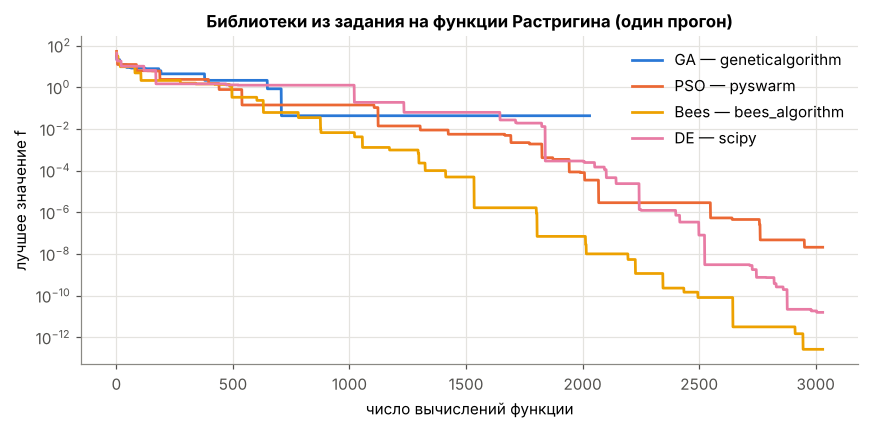

In [9]:
lib_df = pd.DataFrame(lib_results).T
lib_df['f'] = lib_df['f'].astype(float)
lib_df.columns = ['x*', 'f(x*)', 'вычислений f', 'время, с']
display(lib_df.style.format({'f(x*)': '{:.3g}', 'время, с': '{:.2f}'}))

fig, ax = plt.subplots(figsize=(8, 4))
for label, (algo, hist) in lib_curves.items():
    ax.plot(np.arange(1, len(hist) + 1), np.maximum(hist, 1e-16), color=COLORS[algo], label=label)
ax.set_yscale('log'); ax.set_xlabel('число вычислений функции'); ax.set_ylabel('лучшее значение f')
ax.set_title('Библиотеки из задания на функции Растригина (один прогон)')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

**Почему в части B используются собственные реализации.** Для пунктов B.1–B.5 от каждого алгоритма нужно:

* одинаковое правило остановки — и по достижении глобального экстремума (п. 2), и по максимальному числу поколений (п. 3);
* история лучшего значения **и времени** после каждого поколения (п. 3, 4);
* одинаковый бюджет вычислений и одинаковые случайные начальные условия;
* скорость: всего нужно ≈ 15 000 прогонов.

У библиотек нет единого интерфейса для этих вещей. `geneticalgorithm` вызывает функцию через `func_timeout`, поток на каждый вызов, и поэтому очень медленная. `PyACO` вообще решает только задачу коммивояжёра. Поэтому ниже все пять алгоритмов реализованы на NumPy с векторизацией по популяции. Схемы те же, что описаны выше и что используют библиотеки. Демонстрация выше — один прогон каждой библиотеки, поэтому по ней нельзя судить, какой алгоритм лучше: в отдельном прогоне любой из них может и найти глобальный минимум, и застрять в локальном (а `pyswarm` вообще не позволяет зафиксировать `seed`, так что её результат от запуска к запуску меняется). Статистически корректное сравнение по 100 прогонам — в части B.

---
# Часть B. Оптимизация многоэкстремальной функции

### B.1 Функция и условия эксперимента

Функция Растригина — классический тест для глобальной оптимизации: гладкая, сепарабельная, с регулярной сеткой локальных минимумов около целочисленных точек. В области $[-5.12, 5.12]^2$ их $11 \times 11 = 121$, и значения соседних минимумов отличаются примерно на 1. Глобальный минимум — $f(0,0) = 0$.

**Условия эксперимента** (одинаковы для всех ЭА):

| Величина | Значение |
|---|---|
| размер популяции / архива | $N = 30$ (у пчелиного алгоритма — 30 вычислений функции за итерацию) |
| максимальное число поколений | 100, т. е. ≈ 3000 вычислений функции за прогон |
| число прогонов | 100 на алгоритм, с разными `seed` (воспроизводимо) |
| глобальный экстремум найден | $f \le f^* + \varepsilon$, $\varepsilon = 10^{-4}$ |
| дисперсия | несмещённая выборочная, `ddof=1` |
| время | `time.perf_counter()`, мс, включая инициализацию популяции |

In [10]:
N_POP, MAX_GEN = 30, 100          # размер популяции и максимальное число поколений
MAX_GEN_TARGET = 2000             # предел поколений в режиме "до глобального экстремума" (п. 2)
N_RUNS, N_TUNE_RUNS = 100, 100    # прогонов для итоговой оценки и для подбора параметров
SEED_MAIN, SEED_TUNE, SEED_TARGET = 0, 10_000, 20_000
DELTA_LAST = 1e-6                 # точность фиксации "последнего экстремума" (п. 3)

### B.2 Визуализация оптимизируемой функции в трёхмерном пространстве (п. 4)

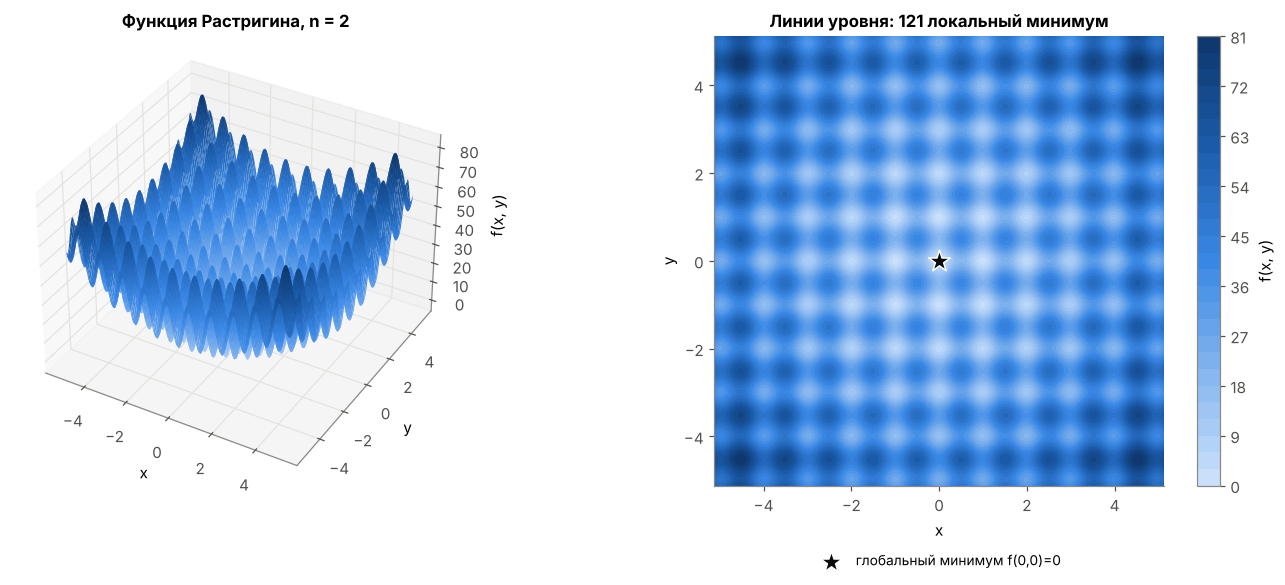

In [11]:
g = np.linspace(-5.12, 5.12, 301)
GX, GY = np.meshgrid(g, g)
GZ = rastrigin(np.stack([GX, GY], axis=-1))

fig = plt.figure(figsize=(13, 5.2))
ax3d = fig.add_subplot(1, 2, 1, projection='3d')
ax3d.plot_surface(GX, GY, GZ, cmap=SEQ_CMAP, rstride=2, cstride=2, linewidth=0, antialiased=True)
ax3d.scatter([0], [0], [0], color='#0b0b0b', s=40, depthshade=False)
ax3d.set_xlabel('x'); ax3d.set_ylabel('y'); ax3d.set_zlabel('f(x, y)')
ax3d.set_title('Функция Растригина, n = 2'); ax3d.view_init(elev=35, azim=-60)

ax2d = fig.add_subplot(1, 2, 2)
cs = ax2d.contourf(GX, GY, GZ, levels=30, cmap=SEQ_CMAP)
ax2d.scatter([0], [0], marker='*', s=220, color='#0b0b0b', edgecolor='white', lw=1, label='глобальный минимум f(0,0)=0')
fig.colorbar(cs, ax=ax2d, label='f(x, y)')
ax2d.set_aspect('equal'); ax2d.set_xlabel('x'); ax2d.set_ylabel('y'); ax2d.grid(False)
ax2d.set_title('Линии уровня: 121 локальный минимум')
ax2d.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), fontsize=9)
plt.tight_layout(); plt.show()

### B.3 Классический алгоритм — метод Ньютона

Метод Ньютона строит квадратичную модель функции по градиенту и гессиану и делает шаг $\mathbf x_{k+1} = \mathbf x_k - H^{-1}(\mathbf x_k)\,\nabla f(\mathbf x_k)$. У функции Растригина гессиан меняет знак, и чистый метод Ньютона может сойтись к максимуму или седлу. Поэтому используется его практическая модификация `Newton-CG` из SciPy: шаг Ньютона находится методом сопряжённых градиентов, при отрицательной кривизне выбирается направление спуска, длина шага подбирается линейным поиском. Метод локальный: он быстро сходится к **ближайшему** к начальной точке минимуму.

* **Один прогон** — старт из случайной точки области, равномерно распределённой; результат — найденное значение $f$ (п. 1).
* Для п. 2 используется **мультистарт**: рестарты из случайных точек, пока не будет найден глобальный минимум. Это единственный способ получить глобальный экстремум локальным методом; время считается суммарно по всем рестартам.

In [12]:
NEWTON_OPTS = {'xtol': 1e-10, 'maxiter': 200}


def newton_run(seed):
    """Один прогон метода Ньютона из случайной точки области."""
    rng = np.random.default_rng(seed)
    x0 = LB + rng.random(2) * (UB - LB)
    t0 = time.perf_counter()
    res = minimize(rastrigin, x0, method='Newton-CG', jac=rastrigin_grad, hess=rastrigin_hess, options=NEWTON_OPTS)
    return dict(x0=x0, x=res.x, f=float(res.fun), time=time.perf_counter() - t0, nfev=res.nfev, nit=res.nit)


def newton_multistart(seed, max_restarts=2000):
    """Мультистарт Ньютона до нахождения глобального минимума (|f - f*| <= EPS)."""
    rng = np.random.default_rng(seed)
    t0, nfev = time.perf_counter(), 0
    for k in range(1, max_restarts + 1):
        x0 = LB + rng.random(2) * (UB - LB)
        res = minimize(rastrigin, x0, method='Newton-CG', jac=rastrigin_grad, hess=rastrigin_hess, options=NEWTON_OPTS)
        nfev += res.nfev
        if res.fun <= F_STAR + EPS:
            return dict(time=time.perf_counter() - t0, restarts=k, nfev=nfev, reached=True)
    return dict(time=time.perf_counter() - t0, restarts=max_restarts, nfev=nfev, reached=False)


newton_run(10**6)                                      # прогрев (первый вызов SciPy медленнее)
newton_runs = [newton_run(SEED_MAIN + i) for i in range(N_RUNS)]
f_newton = np.array([r['f'] for r in newton_runs])
print(f'Ньютон, {N_RUNS} прогонов: среднее f = {f_newton.mean():.4f}, дисперсия = {f_newton.var(ddof=1):.4f}, '
      f'глобальный минимум найден в {np.mean(f_newton <= F_STAR + EPS):.0%} прогонов, '
      f'в среднем {np.mean([r["nit"] for r in newton_runs]):.1f} итераций')

Ньютон, 100 прогонов: среднее f = 16.2177, дисперсия = 124.3805, глобальный минимум найден в 3% прогонов, в среднем 6.2 итераций


### B.4 Собственные реализации эволюционных алгоритмов

Общий интерфейс: `algo(func, lb, ub, ..., max_gen, f_target, seed)` → словарь с лучшей точкой, значением, историей `hist_f` (лучшее значение после каждого поколения) и `hist_t` (время от старта после каждого поколения). Поколение 0 — случайная начальная популяция. Запись истории и правило остановки вынесены в `Tracker`:

* `f_target=None` — остановка только по `max_gen` (пп. 1, 3);
* `f_target=F_STAR` — остановка, как только $f_{best} \le f^* + \varepsilon$ (п. 2).

Функция `func` векторизована: принимает матрицу $(N, n)$ и возвращает вектор $N$ значений.

In [13]:
class Tracker:
    """Лучшее найденное значение и время после каждого поколения + критерий остановки."""
    def __init__(self, f_target=None, eps=EPS):
        self.f_target, self.eps = f_target, eps
        self.best_f, self.best_x = np.inf, None
        self.hist_f, self.hist_t = [], []
        self.nfev = 0
        self.t0 = time.perf_counter()

    def update(self, X, F):
        """Учесть вычисленные точки X со значениями F; вернуть True, если пора остановиться."""
        self.nfev += len(F)
        i = int(np.argmin(F))
        if F[i] < self.best_f:
            self.best_f, self.best_x = float(F[i]), X[i].copy()
        self.hist_f.append(self.best_f)
        self.hist_t.append(time.perf_counter() - self.t0)
        return self.reached()

    def reached(self):
        return self.f_target is not None and self.best_f <= self.f_target + self.eps

    def result(self):
        return dict(x=self.best_x, f=self.best_f, hist_f=np.array(self.hist_f), hist_t=np.array(self.hist_t),
                    nfev=self.nfev, n_gen=len(self.hist_f) - 1, time=self.hist_t[-1], reached=self.reached())


def init_pop(rng, n, lb, ub):
    return lb + rng.random((n, len(lb))) * (ub - lb)

In [14]:
def ga(func, lb, ub, pop_size=30, max_gen=100, pc=0.9, pm=0.1, sigma=0.1, tour=3, alpha=0.5, n_elite=2,
       f_target=None, eps=EPS, seed=None):
    """Вещественный GA: турнирная селекция, BLX-alpha кроссовер, гауссова мутация (sigma — доля ширины области), элитизм."""
    rng = np.random.default_rng(seed)
    span, half = ub - lb, pop_size // 2
    tr = Tracker(f_target, eps)
    X = init_pop(rng, pop_size, lb, ub)
    F = func(X)
    if tr.update(X, F):
        return tr.result()
    for _ in range(max_gen):
        cand = rng.integers(0, pop_size, (2 * half, tour))                      # турниры
        parents = cand[np.arange(2 * half), np.argmin(F[cand], axis=1)]
        P1, P2 = X[parents[:half]], X[parents[half:]]
        lo, hi = np.minimum(P1, P2), np.maximum(P1, P2)
        ext = alpha * (hi - lo)
        do_cx = (rng.random(half) < pc)[:, None]                                # BLX-alpha с вероятностью pc
        C = np.vstack([np.where(do_cx, rng.uniform(lo - ext, hi + ext), P1),
                       np.where(do_cx, rng.uniform(lo - ext, hi + ext), P2)])
        mut = rng.random(C.shape) < pm                                          # гауссова мутация генов
        C = np.clip(C + mut * rng.normal(0.0, sigma * span, C.shape), lb, ub)
        FC = func(C)
        elite, worst = np.argsort(F)[:n_elite], np.argsort(FC)[-n_elite:]       # элитизм
        C[worst], FC[worst] = X[elite], F[elite]
        X, F = C, FC
        if tr.update(X, F):
            break
    return tr.result()

In [15]:
def pso(func, lb, ub, pop_size=30, max_gen=100, w=0.5, c1=0.5, c2=0.5, vmax=0.2,
        f_target=None, eps=EPS, seed=None):
    """Глобальный PSO с инерцией w; скорость ограничена vmax * ширина области."""
    rng = np.random.default_rng(seed)
    vlim = vmax * (ub - lb)
    tr = Tracker(f_target, eps)
    X = init_pop(rng, pop_size, lb, ub)
    V = rng.uniform(-vlim, vlim, X.shape)
    F = func(X)
    P, PF = X.copy(), F.copy()                        # личные лучшие точки
    if tr.update(X, F):
        return tr.result()
    for _ in range(max_gen):
        g = np.argmin(PF)                             # глобальная лучшая точка роя
        r1, r2 = rng.random((2,) + X.shape)
        V = np.clip(w * V + c1 * r1 * (P - X) + c2 * r2 * (P[g] - X), -vlim, vlim)
        X = np.clip(X + V, lb, ub)
        F = func(X)
        imp = F < PF
        P[imp], PF[imp] = X[imp], F[imp]
        if tr.update(X, F):
            break
    return tr.result()

In [16]:
def aco(func, lb, ub, pop_size=30, max_gen=100, n_ants=30, q=0.1, xi=0.85,
        f_target=None, eps=EPS, seed=None):
    """ACO_R (Socha & Dorigo, 2008): архив из pop_size решений, n_ants новых точек за итерацию."""
    rng = np.random.default_rng(seed)
    k = pop_size
    tr = Tracker(f_target, eps)
    S = init_pop(rng, k, lb, ub)
    FS = func(S)
    order = np.argsort(FS)
    S, FS = S[order], FS[order]
    if tr.update(S, FS):
        return tr.result()
    ranks = np.arange(k)
    weights = np.exp(-ranks**2 / (2 * (q * k) ** 2))  # веса решений архива по рангу
    p = weights / weights.sum()
    for _ in range(max_gen):
        l = rng.choice(k, size=n_ants, p=p)                                      # выбор решений-«направляющих»
        sigma = xi * np.abs(S[None, :, :] - S[l][:, None, :]).sum(axis=1) / (k - 1)
        Xn = np.clip(rng.normal(S[l], sigma), lb, ub)                             # новые точки муравьёв
        Fn = func(Xn)
        allS, allF = np.vstack([S, Xn]), np.concatenate([FS, Fn])
        order = np.argsort(allF)[:k]                                             # обновление архива
        S, FS = allS[order], allF[order]
        if tr.update(Xn, Fn):
            break
    return tr.result()

In [17]:
def bees(func, lb, ub, max_gen=100, nb=5, ne=2, nre=8, nrb=3, n_scouts=5, ngh=0.1, shrink=0.8, stlim=10,
         f_target=None, eps=EPS, seed=None):
    """Bees Algorithm (Pham): nb участков (ne элитных), фуражиры nre/nrb на участок, n_scouts разведчиков,
    начальная окрестность ngh (доля ширины области), сужение окрестности shrink, отказ от участка после stlim неудач.
    За итерацию: ne*nre + (nb-ne)*nrb + n_scouts = 30 вычислений функции (по умолчанию)."""
    rng = np.random.default_rng(seed)
    span, d = ub - lb, len(lb)
    tr = Tracker(f_target, eps)
    n_init = ne * nre + (nb - ne) * nrb + n_scouts
    X0 = init_pop(rng, n_init, lb, ub)
    F0 = func(X0)
    order = np.argsort(F0)[:nb]
    X, FX = X0[order], F0[order]
    R, stag = np.full(nb, ngh), np.zeros(nb, dtype=int)     # размер окрестности и счётчик неудач участка
    if tr.update(X0, F0):
        return tr.result()
    counts = np.array([nre] * ne + [nrb] * (nb - ne))
    owner = np.repeat(np.arange(nb), counts)
    starts = np.r_[0, np.cumsum(counts)[:-1]]
    for _ in range(max_gen):
        # локальный поиск фуражиров в окрестностях участков
        Y = np.clip(X[owner] + rng.uniform(-1, 1, (len(owner), d)) * (R[owner, None] * span), lb, ub)
        FY = func(Y)
        best = np.array([s + np.argmin(FY[s:s + c]) for s, c in zip(starts, counts)])
        imp = FY[best] < FX
        X[imp], FX[imp], stag[imp] = Y[best[imp]], FY[best[imp]], 0
        R[~imp] *= shrink                                     # сужение окрестности
        stag[~imp] += 1
        new_X, new_F = [Y], [FY]
        ab = stag > stlim                                     # отказ от участка
        if ab.any():
            X[ab] = init_pop(rng, ab.sum(), lb, ub)
            FX[ab] = func(X[ab])
            R[ab], stag[ab] = ngh, 0
            new_X.append(X[ab]); new_F.append(FX[ab])
        Sc = init_pop(rng, n_scouts, lb, ub)                  # глобальный поиск разведчиков
        FSc = func(Sc)
        new_X.append(Sc); new_F.append(FSc)
        allX, allF = np.vstack([X, Sc]), np.concatenate([FX, FSc])
        allR = np.concatenate([R, np.full(n_scouts, ngh)])
        allS = np.concatenate([stag, np.zeros(n_scouts, dtype=int)])
        order = np.argsort(allF, kind='stable')[:nb]          # новые лучшие участки
        X, FX, R, stag = allX[order], allF[order], allR[order], allS[order]
        if tr.update(np.vstack(new_X), np.concatenate(new_F)):
            break
    return tr.result()

In [18]:
def de(func, lb, ub, pop_size=30, max_gen=100, F=0.8, CR=0.9, f_target=None, eps=EPS, seed=None):
    """Дифференциальная эволюция DE/rand/1/bin."""
    rng = np.random.default_rng(seed)
    n, d = pop_size, len(lb)
    tr = Tracker(f_target, eps)
    X = init_pop(rng, n, lb, ub)
    FX = func(X)
    if tr.update(X, FX):
        return tr.result()
    rows = np.arange(n)
    for _ in range(max_gen):
        idx = rng.random((n, n - 1)).argsort(axis=1)[:, :3]   # три различных индекса, не равных i
        idx += idx >= rows[:, None]
        M = X[idx[:, 0]] + F * (X[idx[:, 1]] - X[idx[:, 2]])   # мутация
        cross = rng.random((n, d)) < CR                        # биномиальное скрещивание
        cross[rows, rng.integers(0, d, n)] = True
        U = np.clip(np.where(cross, M, X), lb, ub)
        FU = func(U)
        better = FU <= FX                                      # жадный отбор
        X[better], FX[better] = U[better], FU[better]
        if tr.update(X, FX):
            break
    return tr.result()


ALGO_FUNCS = {'GA': ga, 'PSO': pso, 'ACO': aco, 'Bees': bees, 'DE': de}


def run_series(name, params, n_runs, seed0, max_gen=MAX_GEN, f_target=None):
    """n_runs независимых прогонов алгоритма name с параметрами params (seed = seed0, seed0+1, ...)."""
    common = {} if name == 'Bees' else {'pop_size': N_POP}
    return [ALGO_FUNCS[name](rastrigin, LB, UB, max_gen=max_gen, f_target=f_target, seed=seed0 + i,
                             **common, **params) for i in range(n_runs)]


# Проверка работоспособности (заодно «прогрев» перед замерами времени)
for name in ALGOS:
    r = run_series(name, {}, 1, seed0=-1 + 10**6)[0]
    print(f'{name:5s} параметры по умолчанию: f = {r["f"]:.3e}, x = {np.round(r["x"], 4)}, '
          f'поколений = {r["n_gen"]}, вычислений f = {r["nfev"]}, время = {r["time"] * 1e3:.1f} мс')

GA    параметры по умолчанию: f = 0.000e+00, x = [-0.  0.], поколений = 100, вычислений f = 3030, время = 28.9 мс
PSO   параметры по умолчанию: f = 0.000e+00, x = [ 0. -0.], поколений = 100, вычислений f = 3030, время = 12.4 мс
ACO   параметры по умолчанию: f = 0.000e+00, x = [ 0. -0.], поколений = 100, вычислений f = 3030, время = 31.9 мс
Bees  параметры по умолчанию: f = 1.471e-05, x = [-0.     -0.0003], поколений = 100, вычислений f = 3032, время = 24.9 мс


DE    параметры по умолчанию: f = 8.344e-11, x = [ 0. -0.], поколений = 100, вычислений f = 3030, время = 16.1 мс


### B.5 Подбор параметров ЭА по минимуму дисперсии (п. 1)

Для каждого алгоритма перебирается сетка значений его основных параметров. Каждая комбинация запускается **100 раз** с отдельной серией `seed` (10000…10099), которая не пересекается с итоговыми прогонами (0…99). Так итоговая оценка в B.6 не смещена самим подбором.

**Критерий** — минимальная дисперсия финального значения $f$ после 100 поколений. Если дисперсии отличаются меньше чем на $10^{-12}$ (практически равны нулю), выбирается меньшее среднее, затем меньшее время.

**Ограничение: конфигурация должна решать задачу** — находить глобальный минимум ($f \le 10^{-4}$) хотя бы в 50 % прогонов. Без этого ограничения минимум дисперсии достигается на *стабильно неточных* конфигурациях. Дисперсию определяют редкие застревания в соседнем локальном минимуме ($f \approx 0.995$): одно такое застревание из 100 прогонов уже даёт $\mathrm{Var} \approx 0.01$. А конфигурация, которая каждый раз останавливается на $f \approx 10^{-3}$ и до глобального минимума не доходит, получает дисперсию порядка $10^{-6}$. Для сравнения в таблице приведён и безусловный минимум дисперсии; на тепловых картах он отмечен пунктирной рамкой, если попадает в показанный срез.

| Алгоритм | Параметры по умолчанию (база) | Сетка |
|---|---|---|
| GA | $p_c=0.9,\ p_m=0.1,\ \sigma=0.1$ | $p_m \in \{0.05, 0.1, 0.2, 0.4\}$, $\sigma \in \{0.01, 0.05, 0.1, 0.2\}$, $p_c \in \{0.6, 0.9\}$ |
| PSO | $w=0.5,\ c_1=c_2=0.5$ (как в `pyswarm`) | $w \in \{0.4, 0.5, 0.6, 0.73, 0.9\}$, $c_1=c_2 \in \{0.5, 1, 1.5, 2\}$ |
| ACO$_\mathbb{R}$ | $q=0.1,\ \xi=0.85$ | $q \in \{0.05, 0.1, 0.2, 0.3, 0.5\}$, $\xi \in \{0.4, 0.6, 0.85, 1\}$ |
| Bees | $ngh=0.1$, сужение 0.8, $stlim=10$ (как в `bees_algorithm`) | $ngh \in \{0.05, 0.1, 0.2\}$, сужение $\in \{0.8, 0.9, 0.95\}$, $stlim \in \{10, 30\}$ |
| DE | $F=0.8,\ CR=0.9$ | $F \in \{0.3, 0.5, 0.65, 0.8, 0.95\}$, $CR \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$ |

In [19]:
DEFAULTS = {'GA': dict(pc=0.9, pm=0.1, sigma=0.1), 'PSO': dict(w=0.5, c1=0.5, c2=0.5),
            'ACO': dict(q=0.1, xi=0.85), 'Bees': dict(ngh=0.1, shrink=0.8, stlim=10), 'DE': dict(F=0.8, CR=0.9)}
GRIDS = {
    'GA':   dict(pm=[0.05, 0.1, 0.2, 0.4], sigma=[0.01, 0.05, 0.1, 0.2], pc=[0.6, 0.9]),
    'PSO':  dict(w=[0.4, 0.5, 0.6, 0.73, 0.9], c1=[0.5, 1.0, 1.5, 2.0]),          # c2 = c1
    'ACO':  dict(q=[0.05, 0.1, 0.2, 0.3, 0.5], xi=[0.4, 0.6, 0.85, 1.0]),
    'Bees': dict(ngh=[0.05, 0.1, 0.2], shrink=[0.8, 0.9, 0.95], stlim=[10, 30]),
    'DE':   dict(F=[0.3, 0.5, 0.65, 0.8, 0.95], CR=[0.1, 0.3, 0.5, 0.7, 0.9]),
}


def expand(name, p):
    p = dict(p)
    if name == 'PSO':
        p['c2'] = p['c1']
    return p


def summarize(runs):
    f = np.array([r['f'] for r in runs])
    t = np.array([r['time'] for r in runs]) * 1e3
    return dict(mean=f.mean(), var=f.var(ddof=1), success=np.mean(f <= F_STAR + EPS), time_ms=t.mean())


MIN_SUCCESS = 0.5     # конфигурация должна находить глобальный минимум хотя бы в половине прогонов

t_tune = time.perf_counter()
tuning, BEST, UNCONSTRAINED = {}, {}, {}
for name in ALGOS:
    rows = []
    for combo in itertools.product(*GRIDS[name].values()):
        p = dict(zip(GRIDS[name], combo))
        rows.append({**p, **summarize(run_series(name, expand(name, p), N_TUNE_RUNS, SEED_TUNE))})
    df = pd.DataFrame(rows)
    key = df.assign(_v=df['var'].round(12), _m=df['mean'].round(12)).sort_values(['_v', '_m', 'time_ms'])
    feasible = key[key['success'] >= MIN_SUCCESS]
    chosen = (feasible if len(feasible) else key).index[0]
    df['лучший'] = df.index == chosen
    df['мин. дисперсии'] = df.index == key.index[0]
    tuning[name] = df
    BEST[name] = expand(name, {k: df.loc[chosen, k] for k in GRIDS[name]})
    UNCONSTRAINED[name] = expand(name, {k: df.loc[key.index[0], k] for k in GRIDS[name]})
print(f'Подбор параметров: {sum(len(d) for d in tuning.values())} комбинаций x {N_TUNE_RUNS} прогонов, '
      f'{time.perf_counter() - t_tune:.0f} c')

def pick_row(a, flag, col):
    return tuning[a].loc[tuning[a][flag], col].iloc[0]


def fmt_params(p):
    return ', '.join(f'{k}={v:g}' for k, v in p.items())


best_tbl = pd.DataFrame({
    'по умолчанию': [', '.join(f'{k}={v}' for k, v in DEFAULTS[a].items()) for a in ALGOS],
    'выбрано': [fmt_params(BEST[a]) for a in ALGOS],
    'дисперсия f': [pick_row(a, 'лучший', 'var') for a in ALGOS],
    'среднее f': [pick_row(a, 'лучший', 'mean') for a in ALGOS],
    'доля глоб. мин.': [pick_row(a, 'лучший', 'success') for a in ALGOS],
    'безусловный мин. дисперсии': [fmt_params(UNCONSTRAINED[a]) for a in ALGOS],
    'его дисперсия f': [pick_row(a, 'мин. дисперсии', 'var') for a in ALGOS],
    'его доля глоб. мин.': [pick_row(a, 'мин. дисперсии', 'success') for a in ALGOS],
}, index=[ALGO_NAMES[a] for a in ALGOS])
print(f'Подобранные параметры (по {N_TUNE_RUNS} прогонов на комбинацию)')
display(best_tbl.style.format({'дисперсия f': '{:.3g}', 'среднее f': '{:.3g}', 'доля глоб. мин.': '{:.0%}',
                               'его дисперсия f': '{:.3g}', 'его доля глоб. мин.': '{:.0%}'}))

Подбор параметров: 115 комбинаций x 100 прогонов, 177 c
Подобранные параметры (по 100 прогонов на комбинацию)


,по умолчанию,выбрано,дисперсия f,среднее f,доля глоб. мин.,безусловный мин. дисперсии,его дисперсия f,его доля глоб. мин.
Генетический,"pc=0.9, pm=0.1, sigma=0.1","pm=0.2, sigma=0.05, pc=0.9",3.88e-10,5.12e-06,99%,"pm=0.2, sigma=0.05, pc=0.9",3.88e-10,99%
Рой частиц,"w=0.5, c1=0.5, c2=0.5","w=0.73, c1=2, c2=2",4.51e-05,0.000822,87%,"w=0.9, c1=1, c2=1",5.21e-06,25%
Муравьиный (ACO_R),"q=0.1, xi=0.85","q=0.3, xi=1",0.0196,0.0208,94%,"q=0.3, xi=1",0.0196,94%
Пчелиный,"ngh=0.1, shrink=0.8, stlim=10","ngh=0.2, shrink=0.8, stlim=10",0.179,0.248,62%,"ngh=0.2, shrink=0.95, stlim=10",0.0695,1%
Дифф. эволюция,"F=0.8, CR=0.9","F=0.5, CR=0.1",2.25e-30,2.13e-16,100%,"F=0.5, CR=0.1",2.25e-30,100%


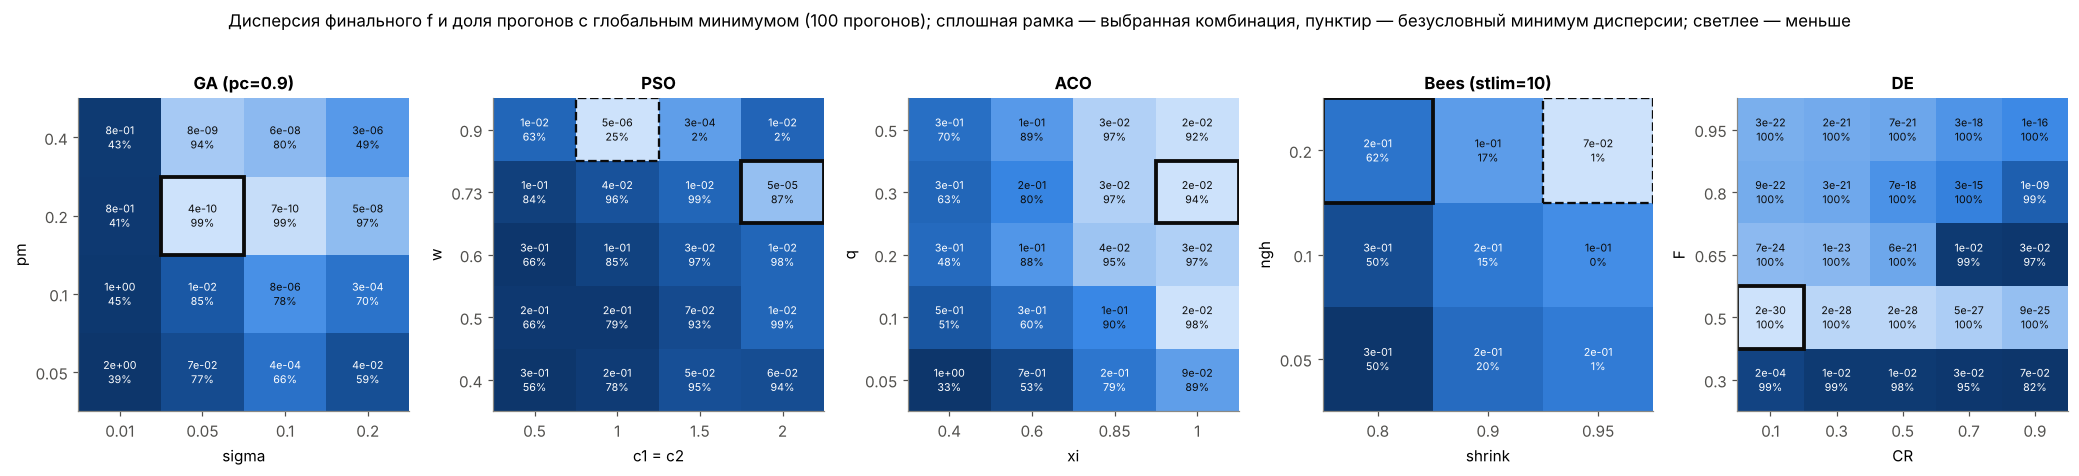

In [20]:
# Тепловые карты дисперсии по двум главным параметрам (остальные параметры — в лучшем значении)
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
for ax, name in zip(axes, ALGOS):
    df, keys = tuning[name], list(GRIDS[name])
    rk, ck = keys[0], keys[1]
    sub = df.copy()
    for other in keys[2:]:
        sub = sub[sub[other] == BEST[name][other]]
    piv = sub.pivot(index=rk, columns=ck, values='var')
    succ = sub.pivot(index=rk, columns=ck, values='success')
    logv = np.log10(np.maximum(piv.values, 1e-30))
    ax.imshow(logv, cmap=SEQ_CMAP, aspect='auto', origin='lower')
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            dark = (logv[i, j] - logv.min()) / (np.ptp(logv) + 1e-12) > 0.55
            ax.text(j, i, f'{v:.0e}\n{succ.values[i, j]:.0%}', ha='center', va='center', fontsize=7,
                    color='white' if dark else '#0b0b0b', linespacing=1.1)
    bi = list(piv.index).index(BEST[name][rk]); bj = list(piv.columns).index(BEST[name][ck])
    ax.add_patch(Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec='#0b0b0b', lw=2.5))
    un = UNCONSTRAINED[name]
    if un != BEST[name] and all(un[o] == BEST[name][o] for o in keys[2:]):
        ui = list(piv.index).index(un[rk]); uj = list(piv.columns).index(un[ck])
        ax.add_patch(Rectangle((uj - 0.5, ui - 0.5), 1, 1, fill=False, ec='#0b0b0b', lw=1.5, ls='--'))
    ax.set_xticks(range(piv.shape[1]), [f'{c:g}' for c in piv.columns])
    ax.set_yticks(range(piv.shape[0]), [f'{r:g}' for r in piv.index])
    ax.set_xlabel('c1 = c2' if ck == 'c1' else ck); ax.set_ylabel(rk); ax.grid(False)
    fixed = ', '.join(f'{o}={BEST[name][o]:g}' for o in keys[2:])
    ax.set_title(f'{name}' + (f' ({fixed})' if fixed else ''))
fig.suptitle(f'Дисперсия финального f и доля прогонов с глобальным минимумом ({N_TUNE_RUNS} прогонов); '
             'сплошная рамка — выбранная комбинация, пунктир — безусловный минимум дисперсии; светлее — меньше',
             fontsize=11, y=1.02)
plt.tight_layout(); plt.show()

### B.6 Среднее и дисперсия финального значения целевой функции, 100 прогонов (п. 1)

Каждый ЭА запускается 100 раз с подобранными параметрами (остановка после 100 поколений), метод Ньютона — 100 раз из случайных начальных точек. Для сравнения приведены и ЭА с параметрами по умолчанию на тех же `seed`.

In [21]:
t_main = time.perf_counter()
main_runs = {name: run_series(name, BEST[name], N_RUNS, SEED_MAIN) for name in ALGOS}
default_runs = {name: run_series(name, DEFAULTS[name], N_RUNS, SEED_MAIN) for name in ALGOS}
print(f'2 x 5 x {N_RUNS} прогонов ЭА: {time.perf_counter() - t_main:.1f} c')


def fitness_row(f, t_ms):
    return {'среднее f': f.mean(), 'дисперсия f': f.var(ddof=1), 'мин f': f.min(), 'макс f': f.max(),
            'доля глоб. минимума': np.mean(f <= F_STAR + EPS),
            'среднее время прогона, мс': t_ms.mean(), 'дисперсия времени, мс²': t_ms.var(ddof=1)}


rows = {'Newton': fitness_row(f_newton, np.array([r['time'] for r in newton_runs]) * 1e3)}
for name in ALGOS:
    rows[name] = fitness_row(np.array([r['f'] for r in main_runs[name]]),
                             np.array([r['time'] for r in main_runs[name]]) * 1e3)
table1 = pd.DataFrame(rows).T
table1.insert(0, 'алгоритм', [ALGO_NAMES[i] for i in table1.index])
FMT = '{:.3g}'
print('Таблица 1. Финальное значение функции соответствия, 100 прогонов (ЭА — подобранные параметры, 100 поколений)')
display(table1.style.format({**{c: FMT for c in table1.columns if c != 'алгоритм'},
                             'доля глоб. минимума': '{:.0%}'}))

cmp = pd.DataFrame({
    'параметры по умолчанию: среднее f': [np.mean([r['f'] for r in default_runs[a]]) for a in ALGOS],
    'по умолчанию: дисперсия f': [np.var([r['f'] for r in default_runs[a]], ddof=1) for a in ALGOS],
    'подобранные: среднее f': [np.mean([r['f'] for r in main_runs[a]]) for a in ALGOS],
    'подобранные: дисперсия f': [np.var([r['f'] for r in main_runs[a]], ddof=1) for a in ALGOS],
}, index=ALGOS)
print('Эффект подбора параметров (те же 100 seed)')
display(cmp.style.format(FMT))

2 x 5 x 100 прогонов ЭА: 14.9 c
Таблица 1. Финальное значение функции соответствия, 100 прогонов (ЭА — подобранные параметры, 100 поколений)


,алгоритм,среднее f,дисперсия f,мин f,макс f,доля глоб. минимума,"среднее время прогона, мс","дисперсия времени, мс²"
Newton,Метод Ньютона,16.2,124,0,40.8,3%,1.49,1.77
GA,Генетический,3.41e-06,6.58e-10,0,0.000254,99%,19.5,30.8
PSO,Рой частиц,4.18e-05,1.25e-08,1.07e-08,0.000794,91%,8.14,5.71
ACO,Муравьиный (ACO_R),0.0199,0.0196,0,0.995,98%,18.9,12.5
Bees,Пчелиный,0.399,0.27,2.13e-14,1.99,54%,15.7,8.3
DE,Дифф. эволюция,3.55e-17,1.26e-31,0,3.55e-15,100%,12.2,12.1


Эффект подбора параметров (те же 100 seed)


,параметры по умолчанию: среднее f,по умолчанию: дисперсия f,подобранные: среднее f,подобранные: дисперсия f
GA,0.0016,8.9e-05,3.41e-06,6.58e-10
PSO,0.507,0.57,4.18e-05,1.25e-08
ACO,0.159,0.254,0.0199,0.0196
Bees,0.508,0.345,0.399,0.27
DE,6.89e-06,3.82e-09,3.55e-17,1.26e-31


### B.7 Время получения априори известного глобального экстремума (п. 2)

ЭА останавливается, как только лучшее значение достигает $f^* + \varepsilon = 10^{-4}$, но не позже 2000 поколений (≈60 000 вычислений функции). Метод Ньютона работает в режиме мультистарта (не более 2000 рестартов). Статистика времени считается по успешным прогонам; доля успешных приведена отдельно.

In [22]:
t_target = time.perf_counter()
target_runs = {name: run_series(name, BEST[name], N_RUNS, SEED_TARGET, max_gen=MAX_GEN_TARGET, f_target=F_STAR)
               for name in ALGOS}
newton_ms = [newton_multistart(SEED_TARGET + i) for i in range(N_RUNS)]
print(f'Прогоны до глобального экстремума: {time.perf_counter() - t_target:.1f} c')


def target_row(times_ms, ok, gens, nfev):
    t = times_ms[ok]
    return {'доля успешных': ok.mean(), 'среднее время, мс': t.mean(), 'дисперсия времени, мс²': t.var(ddof=1),
            'медиана времени, мс': np.median(t), 'среднее поколений / рестартов': gens[ok].mean(),
            'среднее вычислений f': nfev[ok].mean()}


rows = {'Newton': target_row(np.array([r['time'] for r in newton_ms]) * 1e3, np.array([r['reached'] for r in newton_ms]),
                             np.array([r['restarts'] for r in newton_ms]), np.array([r['nfev'] for r in newton_ms]))}
for name in ALGOS:
    rs = target_runs[name]
    rows[name] = target_row(np.array([r['time'] for r in rs]) * 1e3, np.array([r['reached'] for r in rs]),
                            np.array([r['n_gen'] for r in rs]), np.array([r['nfev'] for r in rs]))
table2 = pd.DataFrame(rows).T
table2.insert(0, 'алгоритм', [ALGO_NAMES[i] for i in table2.index])
print('Таблица 2. Время достижения глобального экстремума f* = 0 с точностью 1e-4 (100 прогонов)')
display(table2.style.format({**{c: FMT for c in table2.columns if c != 'алгоритм'},
                             'доля успешных': '{:.0%}', 'среднее поколений / рестартов': '{:.1f}',
                             'среднее вычислений f': '{:.0f}'}))

Прогоны до глобального экстремума: 19.0 c
Таблица 2. Время достижения глобального экстремума f* = 0 с точностью 1e-4 (100 прогонов)


,алгоритм,доля успешных,"среднее время, мс","дисперсия времени, мс²","медиана времени, мс",среднее поколений / рестартов,среднее вычислений f
Newton,Метод Ньютона,100%,131,1.4e+04,92,87.5,1189
GA,Генетический,100%,5.76,10.2,4.79,32.8,1015
PSO,Рой частиц,100%,4.98,1.42,4.96,78.4,2381
ACO,Муравьиный (ACO_R),97%,10.5,10.1,10,59.1,1804
Bees,Пчелиный,100%,22.6,543,12.3,139.7,4227
DE,Дифф. эволюция,100%,4.71,2.45,4.36,39.4,1212


### B.8 Время нахождения последнего (возможно, локального) экстремума при остановке по числу поколений (п. 3)

Используются те же 100 прогонов, что и в п. 1: ЭА всегда работает все 100 поколений. **Последним найденным экстремумом** считается финальное лучшее значение $f_{last}$. **Моментом его нахождения** — первое поколение $g_{last}$, после которого лучшее значение отличается от $f_{last}$ не более чем на $\delta = 10^{-6}$. Время $t_{last}$ — время от старта до конца этого поколения. Порог $\delta$ нужен, потому что ЭА продолжают микроскопически уточнять ответ ($10^{-10}$ и меньше), и без порога «последним улучшением» почти всегда было бы последнее поколение.

Если $g_{last}$ сильно меньше 100, значит, остальное время алгоритм работал впустую: застрял в найденном экстремуме.

In [23]:
def last_extremum(run, delta=DELTA_LAST):
    h = run['hist_f']
    g_last = int(np.argmax(h <= h[-1] + delta))
    return g_last, run['hist_t'][g_last] * 1e3, h[-1]


rows = {}
for name in ALGOS:
    g, t, f = map(np.array, zip(*[last_extremum(r) for r in main_runs[name]]))
    rows[name] = {'среднее t_last, мс': t.mean(), 'дисперсия t_last, мс²': t.var(ddof=1),
                  'среднее g_last': g.mean(), 'дисперсия g_last': g.var(ddof=1),
                  'среднее f_last': f.mean(), 'дисперсия f_last': f.var(ddof=1),
                  'полное время прогона, мс': np.mean([r['time'] for r in main_runs[name]]) * 1e3}
table3 = pd.DataFrame(rows).T
table3.insert(0, 'алгоритм', [ALGO_NAMES[i] for i in table3.index])
print('Таблица 3. Последний найденный экстремум при остановке после 100 поколений (100 прогонов)')
display(table3.style.format({**{c: FMT for c in table3.columns if c != 'алгоритм'}, 'среднее g_last': '{:.1f}'}))

Таблица 3. Последний найденный экстремум при остановке после 100 поколений (100 прогонов)


,алгоритм,"среднее t_last, мс","дисперсия t_last, мс²",среднее g_last,дисперсия g_last,среднее f_last,дисперсия f_last,"полное время прогона, мс"
GA,Генетический,9.06,29.6,45.7,407,3.41e-06,6.58e-10,19.5
PSO,Рой частиц,7.39,5.58,90.2,78.3,4.18e-05,1.25e-08,8.14
ACO,Муравьиный (ACO_R),11.9,11.2,62.8,228,0.0199,0.0196,18.9
Bees,Пчелиный,9.2,12.2,58.3,420,0.399,0.27,15.7
DE,Дифф. эволюция,6.03,3.43,48.8,17.5,3.55e-17,1.26e-31,12.2


### B.9 Визуализация сходимости (п. 4)

1. Лучшее значение целевой функции в зависимости от номера поколения: медиана по 100 прогонам и межквартильный размах. Ось $y$ логарифмическая; нули заменены на $10^{-16}$.
2. Те же кривые для каждого алгоритма отдельно, все 100 прогонов.
3. Где заканчивают прогоны: финальные точки всех алгоритмов на карте линий уровня.
4. Распределения финального значения $f$ (п. 1) и времени до глобального экстремума (п. 2).

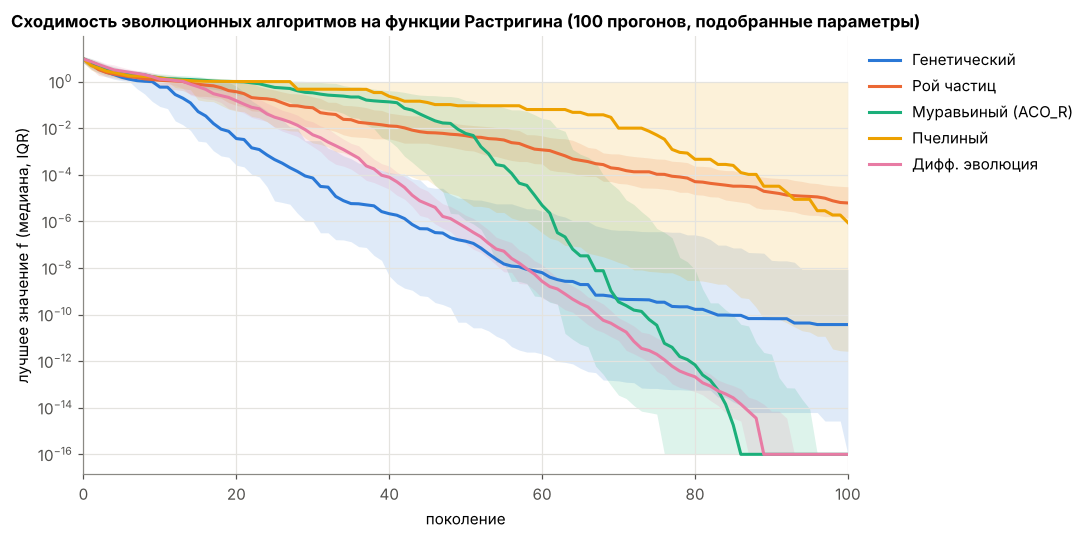

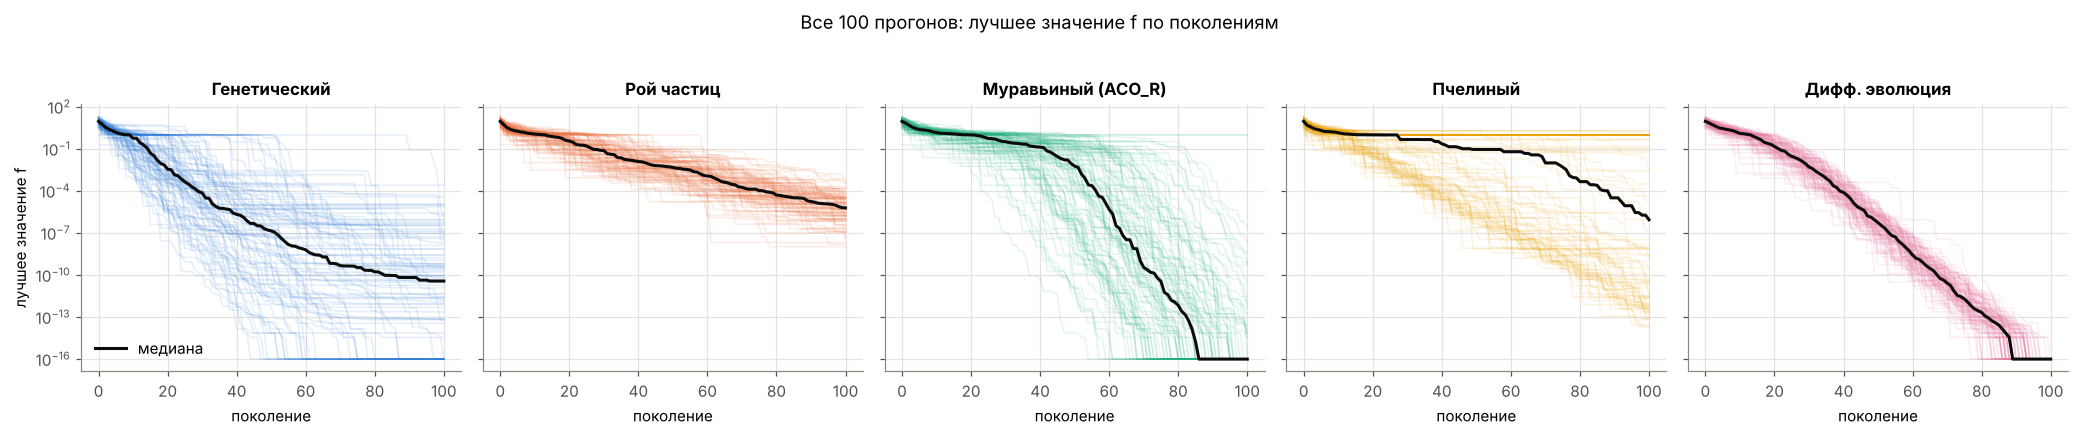

In [24]:
gens = np.arange(MAX_GEN + 1)
H = {name: np.maximum(np.array([r['hist_f'] for r in main_runs[name]]), 1e-16) for name in ALGOS}

fig, ax = plt.subplots(figsize=(10, 5))
for name in ALGOS:
    q25, med, q75 = np.percentile(H[name], [25, 50, 75], axis=0)
    ax.fill_between(gens, q25, q75, color=COLORS[name], alpha=0.15, lw=0)
    ax.plot(gens, med, color=COLORS[name], lw=2, label=ALGO_NAMES[name])
ax.set_yscale('log'); ax.set_xlim(0, MAX_GEN)
ax.set_xlabel('поколение'); ax.set_ylabel('лучшее значение f (медиана, IQR)')
ax.set_title('Сходимость эволюционных алгоритмов на функции Растригина (100 прогонов, подобранные параметры)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
for ax, name in zip(axes, ALGOS):
    ax.plot(gens, H[name].T, color=COLORS[name], alpha=0.12, lw=1)
    ax.plot(gens, np.median(H[name], axis=0), color='#0b0b0b', lw=2, label='медиана')
    ax.set_yscale('log'); ax.set_title(ALGO_NAMES[name]); ax.set_xlabel('поколение')
axes[0].set_ylabel('лучшее значение f'); axes[0].legend(loc='lower left')
fig.suptitle('Все 100 прогонов: лучшее значение f по поколениям', y=1.03)
plt.tight_layout(); plt.show()

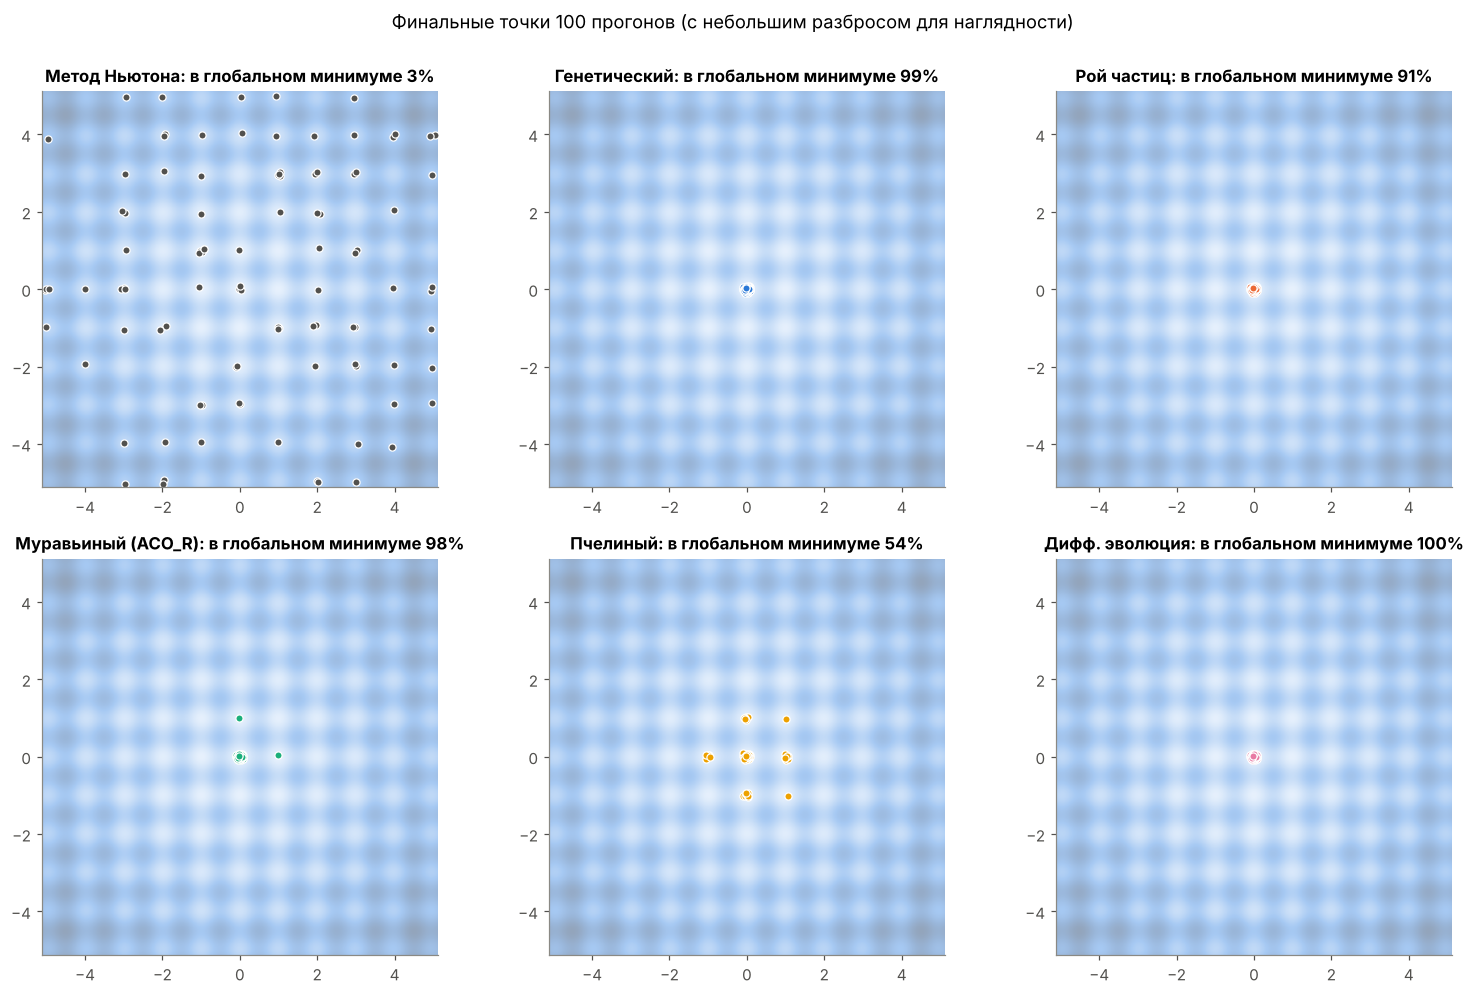

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
panels = [('Newton', np.array([r['x'] for r in newton_runs]))] + \
         [(name, np.array([r['x'] for r in main_runs[name]])) for name in ALGOS]
for ax, (name, pts) in zip(axes.ravel(), panels):
    ax.imshow(GZ, extent=(LB[0], UB[0], LB[1], UB[1]), origin='lower', cmap=SEQ_CMAP, alpha=0.45)
    jitter = np.random.default_rng(0).normal(0, 0.04, pts.shape)        # чтобы совпадающие точки были видны
    ax.scatter(*(pts + jitter).T, s=22, color=COLORS[name], edgecolor='white', lw=0.8)
    f_vals = f_newton if name == 'Newton' else np.array([r['f'] for r in main_runs[name]])
    ax.set_title(f'{ALGO_NAMES[name]}: в глобальном минимуме {np.mean(f_vals <= F_STAR + EPS):.0%}')
    ax.set_xlim(LB[0], UB[0]); ax.set_ylim(LB[1], UB[1]); ax.set_aspect('equal'); ax.grid(False)
fig.suptitle('Финальные точки 100 прогонов (с небольшим разбросом для наглядности)', y=1.0)
plt.tight_layout(); plt.show()

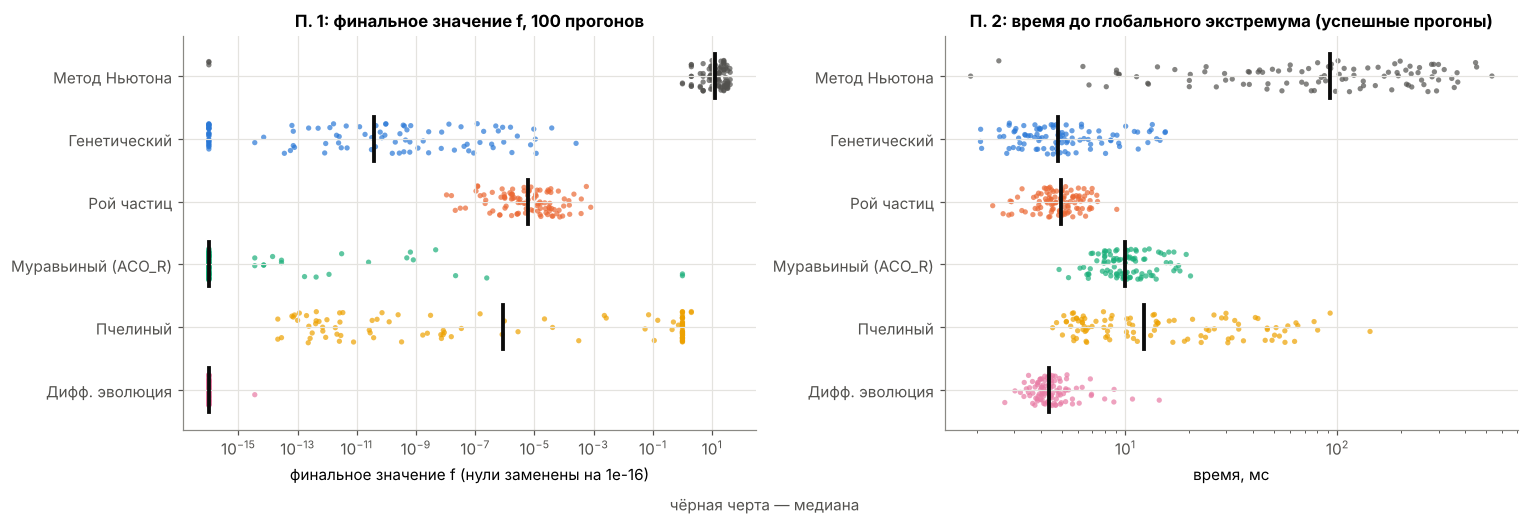

In [26]:
order = ['Newton'] + ALGOS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
rng_j = np.random.default_rng(1)
for i, name in enumerate(order):
    f_vals = f_newton if name == 'Newton' else np.array([r['f'] for r in main_runs[name]])
    ax1.scatter(np.maximum(f_vals, 1e-16), i + rng_j.uniform(-0.25, 0.25, len(f_vals)), s=12,
                color=COLORS[name], alpha=0.7, edgecolor='none')
    if name == 'Newton':
        t_vals = np.array([r['time'] for r in newton_ms if r['reached']]) * 1e3
    else:
        t_vals = np.array([r['time'] for r in target_runs[name] if r['reached']]) * 1e3
    ax2.scatter(t_vals, i + rng_j.uniform(-0.25, 0.25, len(t_vals)), s=12, color=COLORS[name], alpha=0.7,
                edgecolor='none')
    for ax, vals in ((ax1, np.maximum(f_vals, 1e-16)), (ax2, t_vals)):
        ax.plot([np.median(vals)] * 2, [i - 0.35, i + 0.35], color='#0b0b0b', lw=2.5)
for ax in (ax1, ax2):
    ax.set_yticks(range(len(order)), [ALGO_NAMES[n] for n in order]); ax.set_xscale('log'); ax.invert_yaxis()
ax1.set_xlabel('финальное значение f (нули заменены на 1e-16)'); ax1.set_title('П. 1: финальное значение f, 100 прогонов')
ax2.set_xlabel('время, мс'); ax2.set_title('П. 2: время до глобального экстремума (успешные прогоны)')
fig.text(0.5, -0.02, 'чёрная черта — медиана', ha='center', color='#52514e')
plt.tight_layout(); plt.show()

### B.10 Сводная таблица (п. 5)

Среднее и дисперсия по значению целевой функции и по времени для всех алгоритмов в одной таблице.

In [27]:
summary = pd.DataFrame({
    ('f финальное (п. 1)', 'среднее'): table1['среднее f'],
    ('f финальное (п. 1)', 'дисперсия'): table1['дисперсия f'],
    ('время прогона, мс (п. 1)', 'среднее'): table1['среднее время прогона, мс'],
    ('время прогона, мс (п. 1)', 'дисперсия'): table1['дисперсия времени, мс²'],
    ('время до глоб. экстремума, мс (п. 2)', 'среднее'): table2['среднее время, мс'],
    ('время до глоб. экстремума, мс (п. 2)', 'дисперсия'): table2['дисперсия времени, мс²'],
    ('время до глоб. экстремума, мс (п. 2)', 'успех'): table2['доля успешных'],
    ('последний экстремум (п. 3)', 'среднее t_last, мс'): table3['среднее t_last, мс'],
    ('последний экстремум (п. 3)', 'дисп. t_last'): table3['дисперсия t_last, мс²'],
    ('последний экстремум (п. 3)', 'среднее f_last'): table3['среднее f_last'],
    ('последний экстремум (п. 3)', 'дисп. f_last'): table3['дисперсия f_last'],
}).reindex(['Newton'] + ALGOS)
summary.index = [ALGO_NAMES[i] for i in summary.index]
print('Таблица 4. Сводные результаты (дисперсия времени — в мс²; для метода Ньютона п. 2 — мультистарт, п. 3 не применим)')
display(summary.style.format(FMT, na_rep='—')
        .format('{:.0%}', subset=[('время до глоб. экстремума, мс (п. 2)', 'успех')]))

Таблица 4. Сводные результаты (дисперсия времени — в мс²; для метода Ньютона п. 2 — мультистарт, п. 3 не применим)


### Выводы по части B

Абсолютные времена зависят от процессора (в Colab они будут другими), соотношения между алгоритмами при этом сохраняются. Значения $f$ воспроизводятся благодаря фиксированным `seed`.

1. **Метод Ньютона** быстрый: ≈1–2 мс и ≈6 итераций на прогон. Но он строго локальный: из случайной точки сходится к ближайшему из 121 локального минимума. Глобальный минимум найден лишь в **3 %** прогонов; среднее финальное значение ≈ 16.2, дисперсия ≈ 124 — наибольшие среди всех алгоритмов. Финальные точки покрывают всю сетку локальных минимумов (см. рисунок). Чтобы получить глобальный экстремум, мультистарту понадобилось в среднем ≈ 88 рестартов (≈ 130 мс). Число рестартов распределено геометрически, с тяжёлым хвостом, поэтому дисперсия времени очень велика (≈ $1.4\cdot10^4$ мс²).

2. **Эволюционные алгоритмы** уменьшают среднее и дисперсию финального значения на много порядков (п. 1: 100 прогонов, 100 поколений, ≈ 3000 вычислений $f$):
   * **DE** — лучший результат: глобальный минимум в 100 % прогонов, среднее ≈ $4\cdot10^{-17}$, дисперсия ≈ $10^{-31}$ (машинная точность);
   * **GA** — 99 %, среднее ≈ $3\cdot10^{-6}$; точность ограничена фиксированным шагом гауссовой мутации;
   * **PSO** — 91 %; остальные 9 % — не застревания, а недоуточнённые точки рядом с нулём ($f_{max} < 10^{-3}$), среднее ≈ $4\cdot10^{-5}$;
   * **ACO$_\mathbb{R}$** — 98 %, но 2 прогона из 100 застряли в соседнем минимуме $f \approx 0.995$; отсюда дисперсия ≈ 0.02;
   * **пчелиный** — самый слабый: 54 %, среднее ≈ 0.4, дисперсия ≈ 0.27. Локальный поиск быстро стягивает участки в ближайшие минимумы, а 5 разведчиков за итерацию редко находят область лучше.

3. **Подбор параметров** уменьшил дисперсию на порядки: у GA с $9\cdot10^{-5}$ до $7\cdot10^{-10}$, у PSO с 0.57 до $10^{-8}$, у ACO$_\mathbb{R}$ с 0.25 до 0.02, у DE с $4\cdot10^{-9}$ до $10^{-31}$. У пчелиного эффект скромный: с 0.35 до 0.27. Выбранные значения объяснимы. Для DE это малое $CR = 0.1$: функция Растригина сепарабельна, и мутация по одной координате эффективна. Для PSO — классическая инерция $w \approx 0.73$ при $c_1 = c_2 = 2$. Для ACO$_\mathbb{R}$ — более широкий выбор из архива ($q = 0.3$) и медленное сжатие распределения ($\xi = 1$). **Важное наблюдение о критерии:** безусловный минимум дисперсии у PSO ($w = 0.9$, $c = 1$) и у пчелиного ($ngh = 0.2$, сужение 0.95) дают конфигурации, которые почти никогда не доходят до глобального минимума (25 % и 1 % прогонов). Они стабильно неточны, а дисперсию определяют именно редкие застревания. Поэтому дисперсию нужно минимизировать вместе с требованием сходимости, что и сделано.

4. **Время до глобального экстремума (п. 2).** Быстрее всего его находят DE, PSO и GA: ≈ 5–6 мс, ≈ 1000–2400 вычислений $f$. У DE и PSO при этом наименьший разброс времени. ACO$_\mathbb{R}$ тратит ≈ 10 мс, а в 3 % прогонов не находит глобальный минимум даже за 2000 поколений: архив сходится в локальный минимум, и выйти из него алгоритм не может. Пчелиный — ≈ 23 мс с большой дисперсией: выход из локального минимума у него случаен (разведчики, отказ от участка). Мультистарт Ньютона примерно в 20–30 раз медленнее DE. По числу вычислений $f$ он сопоставим (≈ 1200), но каждый рестарт — отдельный вызов оптимизатора, и вдобавок нужны градиент и гессиан.

5. **Последний экстремум при остановке по числу поколений (п. 3).** DE выходит на свой финальный результат в среднем к ≈ 49-му поколению (≈ 6 мс), и разброс этого момента у неё наименьший. GA — к ≈ 46-му, после чего точность почти не растёт. ACO$_\mathbb{R}$ и пчелиный — к ≈ 60-му. PSO улучшает результат почти до конца ($g_{last} \approx 90$). Значит, для DE, GA и ACO$_\mathbb{R}$ бюджет в 100 поколений избыточен примерно вдвое, а PSO нужен весь бюджет или больше. Среднее и дисперсия последнего экстремума совпадают с п. 1, так как это те же прогоны.

6. **Итог.** Классический локальный метод без глобальной стратегии с многоэкстремальной функцией не справляется: он находит лишь ближайший минимум. ЭА находят глобальный экстремум за миллисекунды и без производных. По всем показателям лучшая — дифференциальная эволюция: наименьшие среднее, дисперсия и время, предсказуемая сходимость. Она и используется в части C.

---
# Часть C. Поиск оптимальных гиперпараметров SVM, kNN и RF эволюционным алгоритмом

**Постановка.** Данные `breast_cancer` делятся на обучающую (75 %) и тестовую (25 %) части со стратификацией. Целевая функция для ЭА — средняя accuracy на **5-кратной стратифицированной кросс-валидации** по обучающей части; ЭА минимизирует $1 - \text{accuracy}$. Тестовая часть используется только для итоговой проверки.

**Алгоритм** — дифференциальная эволюция DE/rand/1/bin, реализация из части B. В части B она дала наименьшее среднее и наименьшую дисперсию. Параметры здесь стандартные, $F = 0.7$, $CR = 0.9$: подобранные в части B $CR = 0.1$ хороши для *сепарабельной* функции Растригина, а у гиперпараметров есть взаимодействия (например, $C$ и $\gamma$ у SVM).

**Кодирование гиперпараметров.** Все гены вещественные, при вычислении функции они декодируются:

| Модель | Ген → гиперпараметр | Диапазон |
|---|---|---|
| SVM (`StandardScaler` + `SVC`) | $10^{x_1}$ → `C`; $10^{x_2}$ → `gamma`; $\lfloor x_3 \rfloor$ → `kernel` | $C \in [10^{-2}, 10^{3}]$, $\gamma \in [10^{-5}, 10]$, {rbf, poly, sigmoid} |
| kNN (`StandardScaler` + `KNeighborsClassifier`) | $\lfloor x_1\rfloor$ → `n_neighbors`; $\lfloor x_2\rfloor$ → `weights`; $\lfloor x_3\rfloor$ → `p` | 1…50, {uniform, distance}, {1 (манхэттен), 2 (евклид)} |
| RF (`RandomForestClassifier`) | `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` — целые; `max_features` — доля; `criterion` | 10…100, 1…20, 2…20, 1…10, [0.05, 1], {gini, entropy} |

Одинаковые после округления наборы гиперпараметров не пересчитываются (кэш), поэтому бюджет — число **уникальных** обученных конфигураций.

**Для сравнения** приведены: параметры по умолчанию и `RandomizedSearchCV` с **таким же** числом проверенных конфигураций.

In [28]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import loguniform, randint, uniform

warnings.filterwarnings('ignore')
X_data, y_data = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.25, stratify=y_data, random_state=42)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('train:', X_train.shape, 'test:', X_test.shape, '| доля класса 1:', y_data.mean().round(3))

KERNELS, WEIGHTS, CRITERIA = ['rbf', 'poly', 'sigmoid'], ['uniform', 'distance'], ['gini', 'entropy']


def pick(options, v):
    return options[min(int(v), len(options) - 1)]


SPACES = {
    'SVM': dict(
        make=lambda p: Pipeline([('scaler', StandardScaler()), ('clf', SVC(**p))]),
        decode=lambda v: dict(C=float(10 ** v[0]), gamma=float(10 ** v[1]), kernel=pick(KERNELS, v[2])),
        lb=[-2, -5, 0], ub=[3, 1, 2.999],
        random=dict(clf__C=loguniform(1e-2, 1e3), clf__gamma=loguniform(1e-5, 10), clf__kernel=KERNELS),
        de=dict(pop_size=15, max_gen=15)),
    'kNN': dict(
        make=lambda p: Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(**p))]),
        decode=lambda v: dict(n_neighbors=int(v[0]), weights=pick(WEIGHTS, v[1]), p=pick([1, 2], v[2])),
        lb=[1, 0, 0], ub=[50.999, 1.999, 1.999],
        random=dict(clf__n_neighbors=randint(1, 51), clf__weights=WEIGHTS, clf__p=[1, 2]),
        de=dict(pop_size=10, max_gen=10)),
    'RF': dict(
        make=lambda p: Pipeline([('clf', RandomForestClassifier(random_state=0, **p))]),
        decode=lambda v: dict(n_estimators=int(v[0]), max_depth=int(v[1]), min_samples_split=int(v[2]),
                              min_samples_leaf=int(v[3]), max_features=float(v[4]), criterion=pick(CRITERIA, v[5])),
        lb=[10, 1, 2, 1, 0.05, 0], ub=[100.999, 20.999, 20.999, 10.999, 1.0, 1.999],
        random=dict(clf__n_estimators=randint(10, 101), clf__max_depth=randint(1, 21),
                    clf__min_samples_split=randint(2, 21), clf__min_samples_leaf=randint(1, 11),
                    clf__max_features=uniform(0.05, 0.95), clf__criterion=CRITERIA),
        de=dict(pop_size=12, max_gen=8)),
}


class CVObjective:
    """Целевая функция для ЭА: 1 - accuracy на CV; кэширует уже проверенные наборы гиперпараметров."""
    def __init__(self, space):
        self.space, self.cache, self.log = space, {}, []

    def accuracy(self, v):
        p = self.space['decode'](v)
        key = tuple(sorted(p.items()))
        if key not in self.cache:
            score = cross_val_score(self.space['make'](p), X_train, y_train, cv=CV, scoring='accuracy').mean()
            self.cache[key] = score
            self.log.append(score)                    # порядок уникальных вычислений — для кривых сходимости
        return self.cache[key]

    def __call__(self, P):                            # векторизованный интерфейс, как у rastrigin
        return np.array([1.0 - self.accuracy(v) for v in P])


def test_accuracy(model):
    return model.fit(X_train, y_train).score(X_test, y_test)

train: (426, 30) test: (143, 30) | доля класса 1: 0.627


In [29]:
DE_HP = dict(F=0.7, CR=0.9)
hp_results, hp_curves = {}, {}
for name, space in SPACES.items():
    # 1) параметры по умолчанию
    default_model = space['make']({})
    cv_default = cross_val_score(default_model, X_train, y_train, cv=CV, scoring='accuracy').mean()

    # 2) дифференциальная эволюция
    obj = CVObjective(space)
    t0 = time.perf_counter()
    res = de(obj, np.array(space['lb'], float), np.array(space['ub'], float), seed=0, **space['de'], **DE_HP)
    t_de = time.perf_counter() - t0
    best_p = space['decode'](res['x'])
    n_unique = len(obj.cache)

    # 3) случайный поиск с тем же числом проверенных конфигураций
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(space['make']({}), space['random'], n_iter=n_unique, cv=CV, scoring='accuracy',
                            random_state=0, refit=True).fit(X_train, y_train)
    t_rs = time.perf_counter() - t0

    hp_results[name] = {
        'CV: по умолчанию': cv_default, 'CV: DE': 1 - res['f'], 'CV: случайный поиск': rs.best_score_,
        'тест: по умолчанию': test_accuracy(default_model), 'тест: DE': test_accuracy(space['make'](best_p)),
        'тест: случайный поиск': rs.score(X_test, y_test),
        'конфигураций': n_unique, 'время DE, с': t_de, 'время RS, с': t_rs,
        'лучшие параметры (DE)': ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}' for k, v in best_p.items()),
        'лучшие параметры (RS)': ', '.join(f'{k[5:]}={v:.4g}' if isinstance(v, float) else f'{k[5:]}={v}'
                                           for k, v in rs.best_params_.items()),
    }
    hp_curves[name] = dict(de=np.maximum.accumulate(obj.log), rs=np.maximum.accumulate(rs.cv_results_['mean_test_score']),
                           default=cv_default, gen=1 - res['hist_f'])
    print(f'{name}: DE {t_de:.1f} c, {n_unique} уникальных конфигураций, CV accuracy {1 - res["f"]:.4f} | '
          f'RS {t_rs:.1f} c, CV accuracy {rs.best_score_:.4f}')

SVM: DE 11.4 c, 227 уникальных конфигураций, CV accuracy 0.9766 | RS 14.7 c, CV accuracy 0.9789


kNN: DE 2.6 c, 59 уникальных конфигураций, CV accuracy 0.9695 | RS 2.5 c, CV accuracy 0.9718


RF: DE 94.4 c, 108 уникальных конфигураций, CV accuracy 0.9672 | RS 99.4 c, CV accuracy 0.9648


Таблица 5. Accuracy классификаторов: параметры по умолчанию / дифференциальная эволюция / случайный поиск


,CV: по умолчанию,CV: DE,CV: случайный поиск,тест: по умолчанию,тест: DE,тест: случайный поиск,конфигураций,"время DE, с","время RS, с"
SVM,0.9671,0.9766,0.9789,0.9790,0.9720,0.9860,227,11.4,14.7
kNN,0.9671,0.9695,0.9718,0.9790,0.9650,0.9720,59,2.6,2.5
RF,0.9554,0.9672,0.9648,0.9580,0.9650,0.9580,108,94.4,99.4


Найденные гиперпараметры


,лучшие параметры (DE),лучшие параметры (RS)
SVM,"C=97.06, gamma=0.002155, kernel=rbf","C=30.7, gamma=0.005263, kernel=sigmoid"
kNN,"n_neighbors=9, weights=distance, p=2","n_neighbors=12, p=1, weights=distance"
RF,"n_estimators=63, max_depth=3, min_samples_split=2, min_samples_leaf=1, max_features=0.8308, criterion=entropy","criterion=entropy, max_depth=17, max_features=0.5358, min_samples_leaf=2, min_samples_split=6, n_estimators=78"


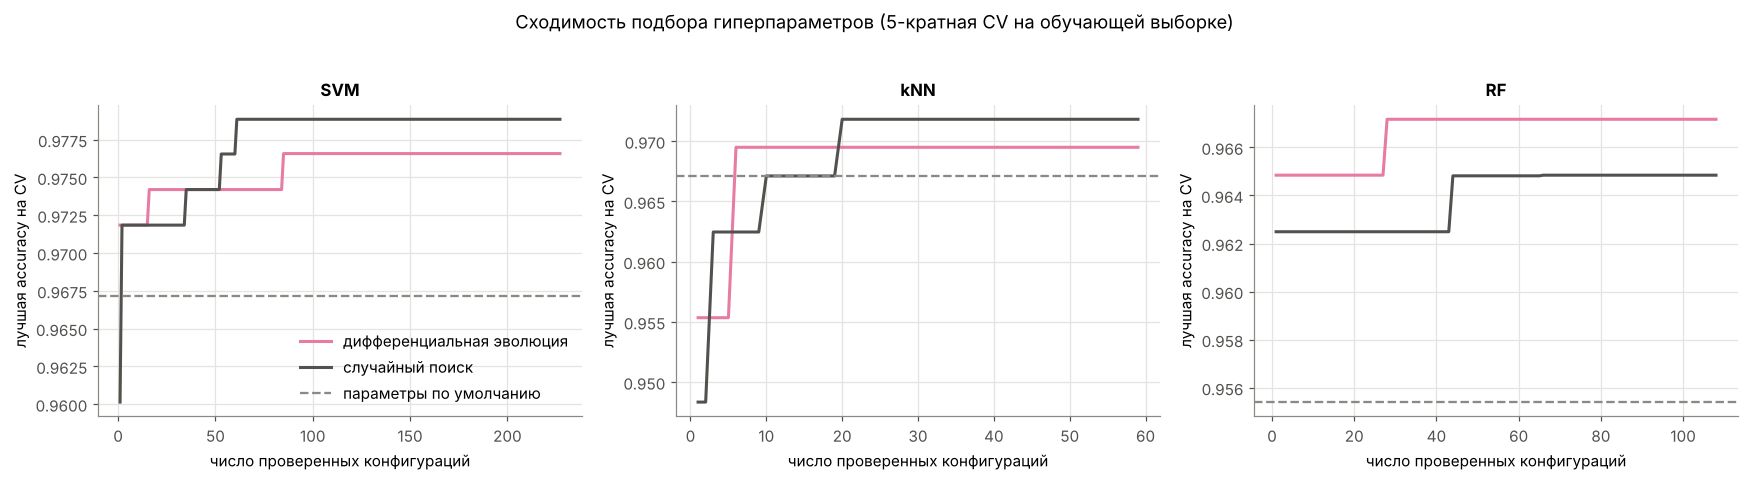

In [30]:
hp_df = pd.DataFrame(hp_results).T
num_cols = [c for c in hp_df.columns if c.startswith(('CV', 'тест'))]
print('Таблица 5. Accuracy классификаторов: параметры по умолчанию / дифференциальная эволюция / случайный поиск')
display(hp_df[num_cols + ['конфигураций', 'время DE, с', 'время RS, с']].astype(float).style
        .format('{:.4f}', subset=num_cols).format('{:.0f}', subset=['конфигураций'])
        .format('{:.1f}', subset=['время DE, с', 'время RS, с']))
print('Найденные гиперпараметры')
display(hp_df[['лучшие параметры (DE)', 'лучшие параметры (RS)']])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, c) in zip(axes, hp_curves.items()):
    ax.plot(np.arange(1, len(c['de']) + 1), c['de'], color=COLORS['DE'], lw=2, label='дифференциальная эволюция')
    ax.plot(np.arange(1, len(c['rs']) + 1), c['rs'], color=COLORS['Newton'], lw=2, label='случайный поиск')
    ax.axhline(c['default'], color='#8a8984', ls='--', lw=1.5, label='параметры по умолчанию')
    ax.set_title(name); ax.set_xlabel('число проверенных конфигураций'); ax.set_ylabel('лучшая accuracy на CV')
axes[0].legend(loc='lower right')
fig.suptitle('Сходимость подбора гиперпараметров (5-кратная CV на обучающей выборке)', y=1.03)
plt.tight_layout(); plt.show()

### Выводы по части C

Конкретные числа могут немного отличаться при других версиях `scikit-learn`.

1. **Подбор дифференциальной эволюцией улучшил accuracy на кросс-валидации у всех трёх моделей** по сравнению с параметрами по умолчанию:
   * SVM: 0.967 → 0.977 ($C \approx 97$, $\gamma \approx 0.002$, ядро RBF);
   * kNN: 0.967 → 0.970 ($k = 9$, взвешивание по расстоянию, евклидова метрика);
   * RF: 0.955 → 0.967 (63 дерева, `max_depth = 3`, `max_features ≈ 0.83`, критерий entropy).
2. **При равном бюджете DE и случайный поиск дали близкие результаты.** В 6-мерном смешанном пространстве RF выиграла DE (0.967 против 0.965). В 3-мерных пространствах SVM и kNN случайный поиск оказался чуть лучше — на 0.2 п. п., то есть на 1 объект из 426. В малой размерности случайный поиск хорошо покрывает пространство. Преимущество ЭА растёт с числом гиперпараметров и с ценой одного обучения.
3. **На тестовой выборке различия статистически незначимы.** В ней 143 объекта, один объект — 0.7 п. п., и все различия укладываются в 1–2 объекта. Для SVM и kNN тестовая accuracy подобранных моделей даже ниже, чем у параметров по умолчанию. Это переобучение на разбиение: модель многократно выбирали по одной и той же CV. Для честной оценки нужна вложенная (nested) CV. На небольшом и хорошо разделимом датасете `breast_cancer` параметры по умолчанию (со стандартизацией признаков) уже близки к оптимальным.
4. **Время подбора определяется ценой одного обучения:** RF — ≈ 90 с на ≈ 100 конфигураций, SVM — ≈ 11 с, kNN — ≈ 2–3 с. Кэш одинаковых после округления конфигураций экономит обучения: у kNN из 110 особей уникальными оказались только 59.

---
## Итог

* **Часть A.** Изучены пять эволюционных алгоритмов (GA, PSO, ACO, пчелиный, DE): их идеи, формулы и параметры. Запущены библиотеки из задания: `geneticalgorithm`, `pyswarm`, `PyACO` (на задаче коммивояжёра), `bees_algorithm`, `scipy.optimize.differential_evolution`.
* **Часть B.** На функции Растригина метод Ньютона сравнён с пятью ЭА. Параметры ЭА подобраны по минимуму дисперсии; посчитаны среднее и дисперсия финального значения, время до глобального экстремума и время нахождения последнего экстремума. Построены 3D-график функции и кривые сходимости, результаты сведены в таблицы.
* **Часть C.** Дифференциальной эволюцией подобраны гиперпараметры SVM, kNN и RF; результат сравнен с параметрами по умолчанию и со случайным поиском при равном бюджете.

In [31]:
total = time.perf_counter() - NOTEBOOK_T0
print(f'Общее время выполнения блокнота: {total / 60:.1f} мин ({total:.0f} c)')

Общее время выполнения блокнота: 7.5 мин (450 c)
